# Notebook 01 — Final Reproducible Evaluation

Run Notebook 02 first. This notebook requires its completed manifest and matching evidence files.

**Delivery status:** source verification and lightweight test results are in `docs/VERIFICATION_REPORT.md`. The production cells are intentionally unexecuted. Full optimisation, final training and held-out evaluation are the student’s Run All responsibilities. No archived output is presented as a fresh result.

[Colab execution guide](../docs/EXECUTION_GUIDE.md) · [Methodology comparison](../docs/METHODOLOGY_PRESERVATION.md) · [Source API](../docs/html/index.html)

These chapters change the presentation, not the original chronological experiment sequence. Mathematical explanations accompany the actual computations. Timed loops and grouped-fold loops remain intact where splitting them would change timing boundaries or execution semantics.

**Contents**

1. Engineering objective and evaluation boundaries
2. Environment, data and fixed split
3. Physical features and numerical verification
4. Authoritative development-manifest import
5. Shared numerical and training interfaces
6. Six final regression models
7. Full-development training and persistence
8. Held-out inference and metric calculation
9. Model-specific final evaluation
10. Generalisation, bias and temperature histories
11. Consistency audit and result export
12. Engineering interpretation and limitations
13. Bibliography


## 1. Engineering objective and evaluation boundaries


The engineering objective is to estimate permanent-magnet temperature (°C) of a PMSM using observable electrical, mechanical and thermal operating conditions. The research aim is to investigate accurate and computationally feasible regression methods using profile-disjoint validation and historical numerical experiments.

**RQ1 — Leakage-safe time-series validation:** How should temporally correlated motor recordings be processed and assigned to folds without overlapping profiles or using future samples in causal features?

**RQ2 — Baseline model accuracy–cost:** Under the original Bayesian optimisations, what accuracy and computational costs arise for OLS, k-NN, Random Forest, Extra Trees and MLP?

**RQ3 — SVR feasibility:** How do exact RBF-SVR, matched-kernel Nyström approximations and direct LinearSVR compare as the number of training observations increases?

**RQ4 — Numerical evidence:** How do numerical checks, grouped-fold variability, timing, convergence and regularisation sensitivity support or limit the development-stage conclusions?

The benchmark [KWB21] motivates the inputs and thermal-memory features. The project’s QR checks, controlled scaling studies, sensitivity experiments and software tests are distinguished from that literature. No new confirmatory hypothesis or numerical finding is invented. Bracketed citations resolve in the bibliography.


### 1.1. Evaluation boundary

The authoritative model settings originate exclusively in Notebook 02’s completed development run. This notebook refits them on all 55 development profiles and predicts the designated 14 held-out profiles. No test score changes a span, parameter, stopping rule or model-selection decision. Historical held-out results have been inspected in prior project iterations; this is a fixed retrospective partition rather than a pristine project-level confirmation.

### 1.2. What is measured

The output is estimated permanent-magnet temperature in °C at the existing 2-Hz source sample positions. Saved source-row indices identify every prediction. The study compares laboratory regression accuracy and computational cost; it does not certify a motor-protection controller.


## 2. Environment, data and fixed split


<a id="s-2-1"></a>

### 2.1. Runtime, portable files and fresh execution

**Research trace:** RQ1–RQ4. Actual source mapping and output register: `docs/EXPERIMENT_REGISTER.md`, final section 2.1.


#### 2.1.1. Purpose

Locate the complete project and record the execution environment without personal Drive paths.


#### 2.1.2. Mathematical basis and assumptions

Identical dataset/source hashes and matching numerical dependency versions are required for an interpretable connection between selection and evaluation. Random seed 42 is preserved; parallel arithmetic can still differ at floating-point roundoff.


#### 2.1.3. Implementation and parameter choices

Use the complete extracted package in Colab or locally. Full mode preserves the original row budgets; smoke mode is a labelled workflow check requiring a legitimate development manifest and cannot supply final scientific evidence.


#### 2.1.4. Results and verification evidence

Environment and output directories are printed and saved. Tests exercise the same reusable package imported here.


#### 2.1.5. Interpretation and limitations

Do not upload only the notebook and omit src/ or the development evidence. The Colab guide explains extraction, installation, runtime restart and handoff transfer.


In [1]:
from pathlib import Path
import os

project = Path(Path("/content/pmsm_project_root.txt").read_text().strip())

os.environ["PMSM_PROJECT_ROOT"] = str(project)
os.environ["PMSM_OUTPUT_DIR"] = str(project / "results")
os.chdir(project)

print("Project ready:", project)

Project ready: /content/MMA3001_Connected_Project/MMA3001_PMSM_Project


In [2]:
# Portable repository bootstrap: run from the repository root or notebooks/.
import os, sys
from pathlib import Path
start = Path(os.environ.get('PMSM_PROJECT_ROOT', Path.cwd())).resolve()
PROJECT_ROOT = next((p for p in [start, *start.parents]
                     if (p / 'src' / 'pmsm_project').is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Extract the complete project; set PMSM_PROJECT_ROOT to its root.')
sys.path.insert(0, str(PROJECT_ROOT / 'src'))
from pmsm_project.data import resolve_csv, file_sha256, validate_dataset
from pmsm_project.validation import allocate_profiles, assert_locked_partition
print('Project root:', PROJECT_ROOT)


Project root: /content/MMA3001_Connected_Project/MMA3001_PMSM_Project


In [3]:
# 1.1.1 — Configuration: single source of truth. No private Drive dependency.
import os, sys, json, gc, time, hashlib, platform, warnings
from pathlib import Path
import numpy as np, pandas as pd, scipy, sklearn, joblib, matplotlib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import TransformedTargetRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.svm import LinearSVR
from sklearn.exceptions import ConvergenceWarning
from scipy.linalg import qr, lstsq
from IPython.display import display

RUN_MODE = os.environ.get('PMSM_RUN_MODE', 'full').strip().lower()  # default = full submission
assert RUN_MODE in {'full','smoke'}
SEED, FS_HZ = 42, 2.0
EXPECTED_SHA256 = '78f3d150f0f2ad9c5dc7ff24dd12c00d386ad530f48c1589ad24fcd88867d3ad'
LOCKED_TEST_IDS = [13,16,23,24,29,42,44,47,53,56,62,67,71,78]
LOCKED_DEVELOPMENT_IDS = [2,3,4,5,6,7,8,9,10,11,12,14,15,17,18,19,20,21,26,27,30,31,32,36,41,43,45,46,48,49,50,51,52,54,55,57,58,59,60,61,63,64,65,66,68,69,70,72,73,74,75,76,79,80,81]

ROOT = Path(os.environ.get('PMSM_OUTPUT_DIR', str(PROJECT_ROOT / 'results')))
OUT = ROOT / RUN_MODE / 'final'
MODELS_DIR, PRED_DIR, RESULTS_DIR, FIG_DIR = (OUT / s for s in ('models','predictions','results','figures'))
for folder in (MODELS_DIR,PRED_DIR,RESULTS_DIR,FIG_DIR): folder.mkdir(parents=True, exist_ok=True)

ENVIRONMENT = {'python':sys.version.split()[0], 'platform':platform.platform(),
 'numpy':np.__version__, 'pandas':pd.__version__, 'scipy':scipy.__version__,
 'sklearn':sklearn.__version__, 'joblib':joblib.__version__,
 'matplotlib':matplotlib.__version__, 'mode':RUN_MODE, 'random_seed':SEED}
(RESULTS_DIR/'environment.json').write_text(json.dumps(ENVIRONMENT,indent=2))
print('RUN MODE:',RUN_MODE,'| Output:',OUT)
print('Environment:',ENVIRONMENT)
if sklearn.__version__ != '1.6.1':
 print('NOTE: Reference training used scikit-learn 1.6.1. Quantitative differences must be documented.')


RUN MODE: full | Output: /content/MMA3001_Connected_Project/MMA3001_PMSM_Project/results/full/final
Environment: {'python': '3.13.16', 'platform': 'Linux-6.6.122+-x86_64-with-glibc2.39', 'numpy': '2.2.6', 'pandas': '2.2.3', 'scipy': '1.15.3', 'sklearn': '1.6.1', 'joblib': '1.5.1', 'matplotlib': '3.10.3', 'mode': 'full', 'random_seed': 42}


In [4]:
if RUN_MODE == 'smoke':
 print('SMOKE MODE: Tests workflow only; NEVER report smoke scores as final scientific results.')


<a id="s-2-2"></a>

### 2.2. Original measurements and byte verification

**Research trace:** RQ1. Actual source mapping and output register: `docs/EXPERIMENT_REGISTER.md`, final section 2.2.


#### 2.2.1. Purpose

Require the same public source data used by the development run.


#### 2.2.2. Mathematical basis and assumptions

Seven measured predictors are ambient and coolant temperature (°C), direct/quadrature voltages $u_d,u_q$ (V), direct/quadrature currents $i_d,i_q$ (A), and speed $n$ (rpm). The five derived predictors are
$$u_s=\sqrt{u_d^2+u_q^2},\quad i_s=\sqrt{i_d^2+i_q^2},\quad S_{el}=1.5u_si_s,\quad i_s\omega,\quad S_{el}\omega,\qquad \omega=2\pi n/60.$$
$S_{el}$ has apparent-power units VA; its speed products are empirical operating-state proxies, not measured rotor heat-generation rates. The target is the measured `pm` temperature $T$ in °C. Stator-temperature channels and torque are retained in the source CSV but excluded from the original seven-input model [KWB21].


#### 2.2.3. Implementation and parameter choices

Resolve the local/public CSV, compute the exact expected SHA-256 and validate all 13 columns, finite values, 69 contiguous profile blocks and 1,330,816 rows.


#### 2.2.4. Results and verification evidence

The validated hash is subsequently matched against the manifest. Optional original-data integration tests independently verify row counts and schema.


#### 2.2.5. Interpretation and limitations

A valid schema alone cannot establish exact data identity. A differently formatted/re-saved CSV must not silently bypass the documented byte contract.


In [5]:
# 1.2.1 — Resolve local or public dataset and verify its exact bytes.
CSV_PATH = resolve_csv(PROJECT_ROOT)
from pmsm_project.data import file_sha256 as sha256_file
SOURCE_HASH=sha256_file(CSV_PATH)
assert SOURCE_HASH == EXPECTED_SHA256, f'Wrong CSV version! SHA256: {SOURCE_HASH}'
raw=pd.read_csv(CSV_PATH)
assert len(raw)==1_330_816 and raw.profile_id.nunique()==69
assert list(raw.columns)==['u_q','coolant','stator_winding','u_d','stator_tooth','motor_speed','i_d','i_q','pm','stator_yoke','ambient','torque','profile_id']
assert raw.isna().sum().sum()==0
assert np.isfinite(raw.select_dtypes(include='number').to_numpy()).all()
block_ids=raw.profile_id.ne(raw.profile_id.shift()).cumsum()
assert block_ids.nunique()==69, 'Profiles are not each in a single chronological block.'
print('PASS: original source verified:',CSV_PATH.name,'| SHA-256:',SOURCE_HASH)
print('Rows:',len(raw),'Profiles:',raw.profile_id.nunique())
DATA_VALIDATION = validate_dataset(raw)


100%|██████████| 117M/117M [00:07<00:00, 16.3MB/s]

Extracting files...


PASS: original source verified: measures_v2.csv | SHA-256: 78f3d150f0f2ad9c5dc7ff24dd12c00d386ad530f48c1589ad24fcd88867d3ad
Rows: 1330816 Profiles: 69


<a id="s-2-3"></a>

### 2.3. Established development and held-out partition

**Research trace:** RQ1. Actual source mapping and output register: `docs/EXPERIMENT_REGISTER.md`, final section 2.3.


#### 2.3.1. Purpose

Verify the exact profile assignment before fitting or prediction.


#### 2.3.2. Mathematical basis and assumptions

The original profile-level temperature-maximum strata and seed-42 split yield 55/14 profiles and 1,055,198/275,618 rows. Each session remains entirely in one partition.


#### 2.3.3. Implementation and parameter choices

Recalculate and assert locked profile IDs, construct full_dev/full_test and save the profile partition figure/table. Descriptive source statistics do not enter hyperparameter tuning.


#### 2.3.4. Results and verification evidence

profile_partition.csv and the duration figure show the original allocation. No profiles are selected according to final model error.


#### 2.3.5. Interpretation and limitations

The prior-inspection limitation remains material even though this execution never feeds held-out errors back into optimisation.


PASS: 55 development profiles / 14 held-out profiles; no overlap.


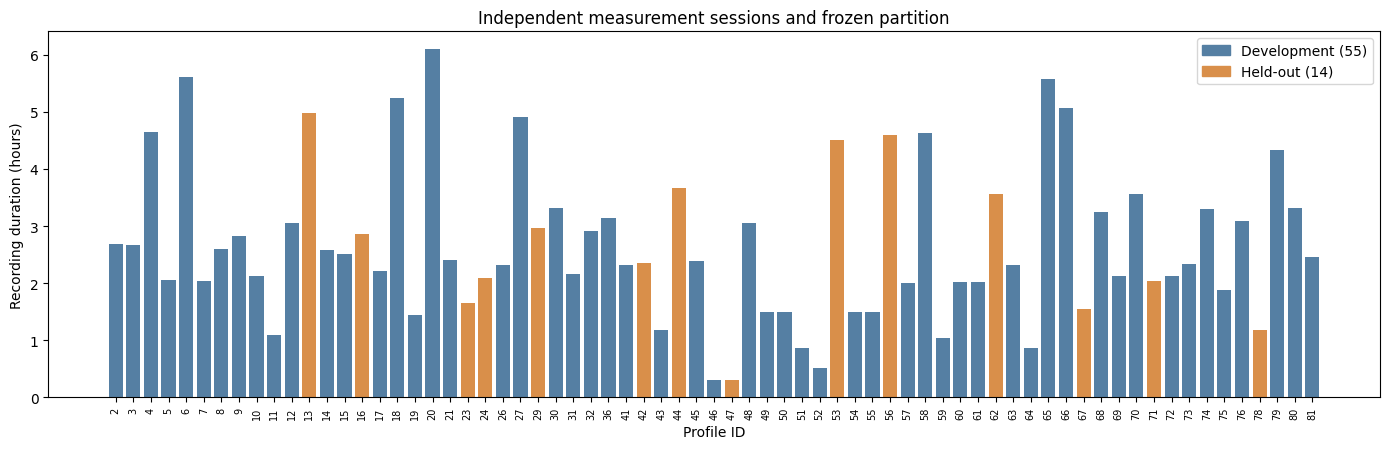

In [6]:
# 2.2.1 — Verify profile partition and visualise size distribution.
profile_summary=(raw.groupby('profile_id',sort=True).agg(observations=('pm','size'),pm_max=('pm','max')).reset_index())
profile_summary['temperature_group']=pd.qcut(profile_summary.pm_max,q=3,labels=['Low','Medium','High'])
recalc_dev,recalc_test=allocate_profiles(profile_summary, test_fraction=0.20, seed=SEED)
assert sorted(map(int,recalc_dev))==LOCKED_DEVELOPMENT_IDS
assert sorted(map(int,recalc_test))==LOCKED_TEST_IDS
assert len(set(LOCKED_DEVELOPMENT_IDS)&set(LOCKED_TEST_IDS))==0
profile_summary['partition']=np.where(profile_summary.profile_id.isin(LOCKED_TEST_IDS),'Held-out','Development')
full_dev=raw.loc[raw.profile_id.isin(LOCKED_DEVELOPMENT_IDS)].copy()
full_test=raw.loc[raw.profile_id.isin(LOCKED_TEST_IDS)].copy()
assert (len(full_dev),len(full_test))==(1_055_198,275_618)
print('PASS: 55 development profiles / 14 held-out profiles; no overlap.')
fig,ax=plt.subplots(figsize=(14,4.6))
colors=profile_summary.partition.map({'Development':'#557fa3','Held-out':'#d98f4a'})
ax.bar(profile_summary.profile_id.astype(str),profile_summary.observations/7200,color=colors)
ax.set(xlabel='Profile ID',ylabel='Recording duration (hours)',title='Independent measurement sessions and frozen partition')
ax.tick_params(axis='x',rotation=90,labelsize=7)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color='#557fa3',label='Development (55)'),Patch(color='#d98f4a',label='Held-out (14)')]);fig.tight_layout()
fig.savefig(FIG_DIR/'02_profile_split.png',dpi=160,bbox_inches='tight');plt.show()
profile_summary.to_csv(RESULTS_DIR/'profile_partition.csv',index=False)
assert_locked_partition(recalc_dev, recalc_test)


## 3. Physical features and numerical verification


<a id="s-3-1"></a>

### 3.1. Canonical physical and temporal features

**Research trace:** RQ1. Actual source mapping and output register: `docs/EXPERIMENT_REGISTER.md`, final section 3.1.


#### 3.1.1. Purpose

Use exactly the same physical/history definition at final training and held-out inference.


#### 3.1.2. Mathematical basis and assumptions

Seven measured predictors are ambient and coolant temperature (°C), direct/quadrature voltages $u_d,u_q$ (V), direct/quadrature currents $i_d,i_q$ (A), and speed $n$ (rpm). The five derived predictors are
$$u_s=\sqrt{u_d^2+u_q^2},\quad i_s=\sqrt{i_d^2+i_q^2},\quad S_{el}=1.5u_si_s,\quad i_s\omega,\quad S_{el}\omega,\qquad \omega=2\pi n/60.$$
$S_{el}$ has apparent-power units VA; its speed products are empirical operating-state proxies, not measured rotor heat-generation rates. The target is the measured `pm` temperature $T$ in °C. Stator-temperature channels and torque are retained in the source CSV but excluded from the original seven-input model [KWB21].

For a span $s$ measured in samples, $\alpha=2/(s+1)$ and $w_{t,j}=(1-\alpha)^{t-j}$ for $j\leq t$. The adjusted mean and biased standard deviation are
$$\mu_t=\frac{\sum_{j=0}^{t}w_{t,j}x_j}{\sum_{j=0}^{t}w_{t,j}},\qquad
\sigma_t=\sqrt{\frac{\sum_{j=0}^{t}w_{t,j}(x_j-\mu_t)^2}{\sum_{j=0}^{t}w_{t,j}}}.$$
Pandas `adjust=True` and `std(bias=True)` implement these moments [PANDAS]. Thus $\mu_0=x_0$ and $\sigma_0=0$. Four spans for each of 12 inputs give $12+2(12)(4)=108$ features. Filters reset at every recording and use full original chronological histories before selecting rows. A span of 200 samples corresponds to 100 s of sample count at 2 Hz; an exponential filter has infinite decaying support rather than a hard 100-s window.


#### 3.1.3. Implementation and parameter choices

feature_frame and feature_names enforce the original variable-major feature order. Each model receives its own freshly selected spans. The illustrative EWMA plot uses fixed diagnostic spans only; these do not replace model selections.


#### 3.1.4. Results and verification evidence

The saved current-memory plot illustrates the filter response. The shared production functions are checked for feature identity, reset behaviour, causality and invalid input handling.


#### 3.1.5. Interpretation and limitations

A model using the current and past measured covariates is causal in its feature information. Its numerical regression weights do not establish a physical heat-balance model.


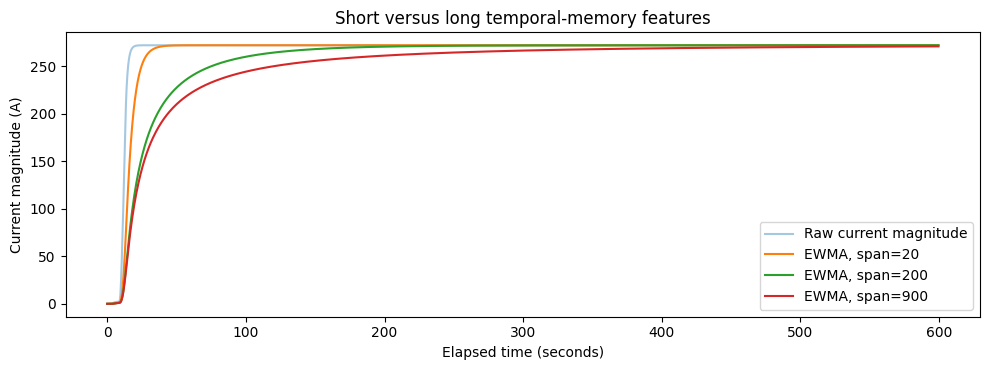

In [7]:
# 3.2.1 — One canonical feature function for training AND held-out inference.
BASE_COLS=['theta_a','theta_c','u_d','u_q','i_d','i_q','n_mech','u_s','i_s','S_el','i_s_omega','S_el_omega']
from pmsm_project.features import make_paper_inputs

from pmsm_project.features import feature_names

from pmsm_project.features import feature_frame

# Demonstrate EWMA memory using one development profile; no model is fitted.
pid=LOCKED_DEVELOPMENT_IDS[0];pr=full_dev.loc[full_dev.profile_id.eq(pid)].iloc[:1200]
base=make_paper_inputs(pr);sig=base['i_s']
fig,ax=plt.subplots(figsize=(10,3.8))
t=np.arange(len(sig))/FS_HZ
ax.plot(t,sig.to_numpy(),alpha=.4,label='Raw current magnitude')
for s in (20,200,900):ax.plot(t,sig.ewm(span=s,adjust=True).mean().to_numpy(),label=f'EWMA, span={s}')
ax.set(xlabel='Elapsed time (seconds)',ylabel='Current magnitude (A)',title='Short versus long temporal-memory features');ax.legend();fig.tight_layout()
fig.savefig(FIG_DIR/'03_ewma_memory.png',dpi=160,bbox_inches='tight');plt.show()


<a id="s-3-2"></a>

### 3.2. Numerical checks and grouped-fold compatibility

**Research trace:** RQ1, RQ4. Actual source mapping and output register: `docs/EXPERIMENT_REGISTER.md`, final section 3.2.


#### 3.2.1. Purpose

Verify the feature equations and independently regenerate the development fold map before importing selections.


#### 3.2.2. Mathematical basis and assumptions

For a span $s$ measured in samples, $\alpha=2/(s+1)$ and $w_{t,j}=(1-\alpha)^{t-j}$ for $j\leq t$. The adjusted mean and biased standard deviation are
$$\mu_t=\frac{\sum_{j=0}^{t}w_{t,j}x_j}{\sum_{j=0}^{t}w_{t,j}},\qquad
\sigma_t=\sqrt{\frac{\sum_{j=0}^{t}w_{t,j}(x_j-\mu_t)^2}{\sum_{j=0}^{t}w_{t,j}}}.$$
Pandas `adjust=True` and `std(bias=True)` implement these moments [PANDAS]. Thus $\mu_0=x_0$ and $\sigma_0=0$. Four spans for each of 12 inputs give $12+2(12)(4)=108$ features. Filters reset at every recording and use full original chronological histories before selecting rows. A span of 200 samples corresponds to 100 s of sample count at 2 Hz; an exponential filter has infinite decaying support rather than a hard 100-s window.

Each profile belongs to one validation fold. Its other two folds provide the fitting profiles. For fold $f$,
$$MSE_f=\frac1{N_f}\sum_{i\in f}(\hat T_i-T_i)^2,\qquad J=\frac13\sum_{f=1}^{3}MSE_f.$$
The objective $J$ has units °C² and weights folds equally. It is different from pooling every validation row before calculating MSE. Feature and target standardisers are fitted only on the fitting profiles and predictions are inverse-transformed before scoring. Profile-level temperature maxima define three strata for the fixed shuffled `StratifiedKFold(3, random_state=42)` assignment [ROBERTS17].


#### 3.2.3. Implementation and parameter choices

Retain the original pandas moment checks and grouped-fold schematic. This notebook derives the original assignments but performs no hyperparameter optimisation on them.


#### 3.2.4. Results and verification evidence

108-feature moment parity, first-sample limits and the fold table are checked. The loader compares this independently reconstructed fold map with Notebook 02’s evidence.


#### 3.2.5. Interpretation and limitations

The checks establish implementation/selection compatibility. They do not replace the final held-out measurements or prove generalisation outside the data domain.


PASS: 108 features and temporal moments match the independent pandas reference.


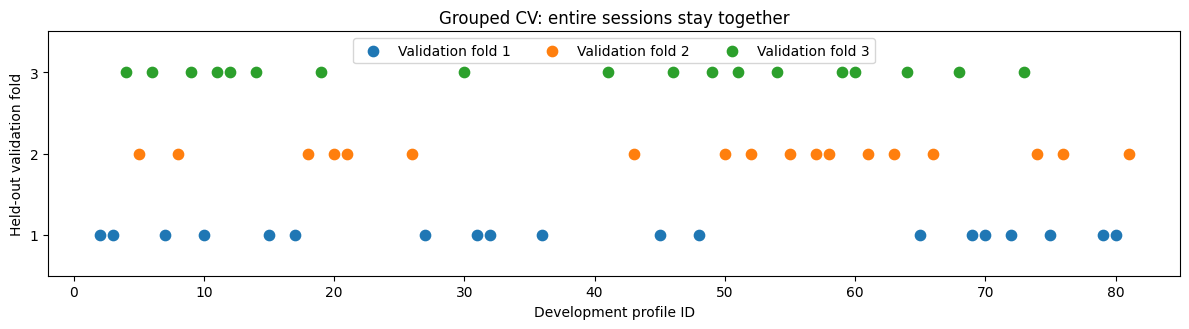

In [8]:
# 4.1.1 — Numerical feature checks, plus development-only fold schematic.
p=full_dev.loc[full_dev.profile_id.eq(LOCKED_DEVELOPMENT_IDS[0])].iloc[:30]
a=feature_frame(p,(10,50,200,1000));b=make_paper_inputs(p)
for col in BASE_COLS:
    for s in (10,50,200,1000):
        ref=b[col].ewm(span=s,adjust=True)
        np.testing.assert_allclose(a[f'{col}_ewma_s{s}'].to_numpy(),ref.mean().to_numpy(),atol=1e-12)
        np.testing.assert_allclose(a[f'{col}_ewms_s{s}'].to_numpy(),ref.std(bias=True).to_numpy(),atol=1e-12)
        assert abs(a[f'{col}_ewma_s{s}'].iloc[0]-b[col].iloc[0])<1e-9
        assert abs(a[f'{col}_ewms_s{s}'].iloc[0])<1e-9
print('PASS: 108 features and temporal moments match the independent pandas reference.')
cv=profile_summary.loc[profile_summary.partition.eq('Development'),['profile_id','pm_max','observations']].copy().reset_index(drop=True)
cv['strata']=pd.qcut(cv.pm_max,q=3,labels=['Low','Medium','High']);cv['fold']=0
skf=StratifiedKFold(n_splits=3,shuffle=True,random_state=SEED)
for fold,(_,val_idx) in enumerate(skf.split(cv[['pm_max']],cv.strata),start=1):cv.loc[val_idx,'fold']=fold
assert len(cv)==55 and set(cv.fold)=={1,2,3}
fig,ax=plt.subplots(figsize=(12,3.4));z=cv.sort_values('profile_id')
for k in (1,2,3):
    y=np.where(z.fold.eq(k),k,np.nan)
    ax.scatter(z.profile_id,y,s=55,label=f'Validation fold {k}')
ax.set(yticks=[1,2,3],ylim=(0.5,3.5),xlabel='Development profile ID',ylabel='Held-out validation fold',title='Grouped CV: entire sessions stay together');ax.legend(ncol=3,loc='upper center');fig.tight_layout()
fig.savefig(FIG_DIR/'04_grouped_cv.png',dpi=160,bbox_inches='tight');plt.show()
cv.to_csv(RESULTS_DIR/'development_cv_folds.csv',index=False)


## 4. Authoritative development-manifest import


<a id="s-4-1"></a>

### 4.1. Strict import and six-model agreement

**Research trace:** RQ1–RQ4. Actual source mapping and output register: `docs/EXPERIMENT_REGISTER.md`, final section 4.1.


#### 4.1.1. Purpose

Eliminate the historical-configuration fallback and verify that final training uses the actual current development selections.


#### 4.1.2. Mathematical basis and assumptions

The manifest is a sealed JSON record with evidence CSV hashes, original search bounds/budgets, grouped-fold assignments, dataset/code hashes and numerical versions. The loader recomputes selected minima from the evidence.


#### 4.1.3. Implementation and parameter choices

load_manifest stops for missing, incompatible, altered, incomplete or smoke evidence. SELECTED is copied only from its validated models mapping; build_pipeline requires that mapping explicitly. No frozen_configurations function exists in production.


#### 4.1.4. Results and verification evidence

configuration_agreement displays all six imported spans/parameter mappings and asserts equality before any fit. The imported manifest and agreement CSV are preserved in final results.


#### 4.1.5. Interpretation and limitations

Integrity hashes detect accidental mismatches; they are not a cryptographic signature of authorship. Unit-test fixture manifests are labelled synthetic and are never shipped as production selections.


In [9]:
# Only the completed development manifest is authoritative.
from copy import deepcopy
from pmsm_project.config import TRAIN_ORDER, REPORT_ORDER
from pmsm_project.handoff import load_manifest, configuration_agreement
MANIFEST_PATH=Path(os.environ.get('PMSM_CONFIG_MANIFEST',ROOT/'full/development/development_selected_configurations.json'))
if not MANIFEST_PATH.is_absolute():MANIFEST_PATH=PROJECT_ROOT/MANIFEST_PATH
DEVELOPMENT_MANIFEST=load_manifest(MANIFEST_PATH,project_root=PROJECT_ROOT,
    dataset_hash=SOURCE_HASH,profile_cv=cv.rename(columns={'fold':'cv_fold'}))
SELECTED=deepcopy(DEVELOPMENT_MANIFEST['models'])
AGREEMENT=configuration_agreement(DEVELOPMENT_MANIFEST,SELECTED)
display(AGREEMENT)
assert len(AGREEMENT)==6 and AGREEMENT.Agrees.all()
(RESULTS_DIR/'imported_development_manifest.json').write_text(json.dumps(DEVELOPMENT_MANIFEST,indent=2))
AGREEMENT.to_csv(RESULTS_DIR/'configuration_agreement.csv',index=False)
print('Verified development run:',DEVELOPMENT_MANIFEST['run']['id'])
print('Verified manifest SHA-256:',DEVELOPMENT_MANIFEST['manifest_sha256'])


,Model,Spans_samples,Hyperparameters,Selection_source,Agrees
0,OLS,"[67, 97, 693, 3339]",{},current-run 20-evaluation full-development QR ...,True
1,k-NN,"[89, 96, 1252, 7227]","{""n_neighbors"": 54, ""weights"": ""distance""}",current-run 12-evaluation larger GP search,True
2,Extra Trees,"[46, 182, 620, 4544]","{""bootstrap"": ""yes"", ""max_depth"": 26, ""min_sam...",current-run 12-evaluation larger GP search,True
3,MLP,"[52, 407, 647, 6467]","{""alpha"": 0.007211746678427099, ""learning_rate...",current-run 12-evaluation larger GP search,True
4,Random Forest,"[99, 152, 1640, 7415]","{""bootstrap"": ""yes"", ""max_depth"": 30, ""min_sam...",current-run 12-evaluation larger GP search,True
5,LinearSVR,"[91, 358, 1712, 7591]","{""C"": 0.0010983198718170478, ""dual"": true, ""ep...",current-run Stage 9J/9K converged minimum,True


Verified development run: d9ae4c0a-aa9f-4400-9e2a-88d11f3bfe36
Verified manifest SHA-256: 57a55568b5abae9c9dc89596d14883b56f44b2ecf55bfe1b282c057adb1fdb94


## 5. Shared numerical and training interfaces


<a id="s-5-1"></a>

### 5.1. Profile-wise augmented QR and independent identity

**Research trace:** RQ4. Actual source mapping and output register: `docs/EXPERIMENT_REGISTER.md`, final section 5.1.


#### 5.1.1. Purpose

Verify the final linear solver’s objective before the full-development fit.


#### 5.1.2. Mathematical basis and assumptions

Let $A_p=[\mathbf1,X_p,y_p]$ for profile $p$, with $A_p=Q_pR_p$. For $v=(b,\beta^T,-1)^T$, orthogonality gives $\|A_pv\|_2^2=\|R_pv\|_2^2$. Therefore stacking the small $R_p$ factors preserves the least-squares objective of all original rows. Training-fold feature moments are combined using
$$\mu=\frac{\sum_p n_p\mu_p}{N},\qquad v_X=\frac{\sum_p n_p[v_p+(\mu_p-\mu)^2]}{N}.$$
The augmented intercept column permits the equivalent scaling transformation without rebuilding a full design matrix. `scipy.linalg.lstsq(..., lapack_driver='gelsd')` provides a rank-aware SVD solve [SCIPY]. No normal-equation inverse is formed. Numerical rank, residual norms and predictions are more informative than individual coefficients in a nearly dependent design.


#### 5.1.3. Implementation and parameter choices

Retain qr_compress_profile, fit_qr_ols and the independent synthetic direct-lstsq comparison. The final OLS training receives only the manifest-selected spans.


#### 5.1.4. Results and verification evidence

The numerical identity assertion compares compressed and direct solutions using documented floating-point tolerances. fit_qr_ols later records rank and row count.


#### 5.1.5. Interpretation and limitations

Rank deficiency may arise for freshly selected spans. Rank is retained as a diagnostic rather than imposing an archived rank-109 outcome.


In [10]:
# 6.1.1 — Reproduced original profile-wise QR method.
from pmsm_project.numerics import qr_compress_profile

from pmsm_project.numerics import fit_qr_ols

# Independent synthetic-data check: augmented QR and ordinary lstsq agree.
rng=np.random.default_rng(SEED)
xx=rng.normal(size=(400,8));yy=xx@rng.normal(size=8)+rng.normal(scale=.01,size=400)
A=np.column_stack((np.ones(len(xx)),xx));R=qr(np.column_stack((A,yy)),mode='r')[0]
a=lstsq(R[:,:-1],R[:,-1])[0];b=lstsq(A,yy)[0]
np.testing.assert_allclose(a,b,rtol=1e-8,atol=1e-8)
print('PASS: QR-compressed least squares matches a direct independent solver.')


PASS: QR-compressed least squares matches a direct independent solver.


<a id="s-5-2"></a>

### 5.2. Training matrix and estimator factories

**Research trace:** RQ1, RQ2, RQ3. Actual source mapping and output register: `docs/EXPERIMENT_REGISTER.md`, final section 5.2.


#### 5.2.1. Purpose

Provide one explicit interface for all selected scaled models and complete profile histories.


#### 5.2.2. Mathematical basis and assumptions

For scaled models, input and target moments use development observations only. Temperature predictions are inverse-transformed to °C. OLS retains its original raw-target QR solve.


#### 5.2.3. Implementation and parameter choices

build_training_matrix assembles 108 features/profile using model-specific spans. build_pipeline retains each original architecture, solver and worker setting. The construction check verifies fit/predict interfaces without training.


#### 5.2.4. Results and verification evidence

All factories accept the selected mapping. Serialization and deterministic-operation tests exercise actual production estimators; no previously saved model is restored before fitting.


#### 5.2.5. Interpretation and limitations

The larger/final MLP row-based early-stopping split is preserved and disclosed. Final fit timers exclude some common feature-construction work, whereas OLS’s recorded routine includes QR feature/compression work; these are not identical benchmark boundaries.


In [11]:
# 7.2.1 — Single model factory and profile-wise training matrix.
from pmsm_project.models import build_pipeline

def relevant_profiles(df,is_test=False):
    """Return original chronological profile blocks for the selected run mode.

    Parameters
    ----------
    df : pandas.DataFrame
        Raw chronological source rows, with profile_id and pm in °C.
    is_test : bool, default False
        Select the original smoke-prefix length; full mode always retains all rows.

    Returns
    -------
    list[tuple[int, pandas.DataFrame]]
        Complete profiles in full mode; labelled early-prefix workflow fixtures in smoke mode.

    Raises
    ------
    ValueError, TypeError
        If stage inputs or underlying estimator settings are incompatible.

    Notes
    -----
    Uses this section’s current-run state and original numerical statements.
    Refer to the numbered mathematics, results and limitations immediately above.
    """
    groups=df.groupby('profile_id',sort=False)
    if RUN_MODE=='full': return [(int(pid),block) for pid,block in groups]
    # Only a small early-time prefix of each session: workflow verification, not science.
    return [(int(pid),block.iloc[:120 if not is_test else 160]) for pid,block in groups]


In [12]:
def build_training_matrix(data,spans):
    """Assemble the original model-specific full-development feature matrix.

    Parameters
    ----------
    data : pandas.DataFrame
        Raw chronological source rows; target pm in °C.
    spans : sequence[int]
        Four ordered temporal spans in original 2-Hz samples.

    Returns
    -------
    tuple
        Float64 predictors, target temperatures (°C), exact feature names and profile count.

    Raises
    ------
    ValueError, TypeError
        If stage inputs or underlying estimator settings are incompatible.

    Notes
    -----
    Uses this section’s current-run state and original numerical statements.
    Refer to the numbered mathematics, results and limitations immediately above.
    """
    blocks=relevant_profiles(data)
    n=sum(len(p) for _,p in blocks);names=feature_names(spans)
    X=np.empty((n,108),dtype=np.float64);y=np.empty(n,dtype=np.float64)
    cursor=0
    for pid,profile in blocks:
        features=feature_frame(profile,spans)
        nxt=cursor+len(profile)
        X[cursor:nxt]=features[names].to_numpy(dtype=np.float64)
        y[cursor:nxt]=profile.pm.to_numpy(dtype=np.float64)
        cursor=nxt
    assert cursor==n and np.isfinite(X).all() and np.isfinite(y).all()
    return X,y,names,len(blocks)


In [13]:
# IMPORTANT: this is an explicit test of the model construction, not a model fit.
for name in [s for s in TRAIN_ORDER if s!='OLS']:
    p=build_pipeline(name, SELECTED); assert hasattr(p,'fit')
print('PASS: Model pipeline factory and all six imported configurations ready.')


PASS: Model pipeline factory and all six imported configurations ready.


## 6. Six final regression models

The following model sections explain the six estimators before the original common training loop. Training order remains OLS, k-NN, Extra Trees, MLP, Random Forest, LinearSVR. Their individual final evaluation tables are generated in Chapter 9 after the common held-out inference stage.


<a id="s-6-1"></a>

### 6.1. OLS

**Research trace:** RQ2, RQ3, RQ4. Final training: Chapter 7; model-specific results: section 9.1; factory: pmsm_project.models / pmsm_project.numerics.


#### 6.1.1. Purpose

Fit and evaluate OLS as one of the six originally selected final regression families.


#### 6.1.2. Mathematical basis and assumptions

OLS predicts $\hat T=b+x^T\beta$ and minimises $\sum_i(T_i-b-x_i^T\beta)^2$. The final fit uses profile-wise augmented QR compression, development-only feature moments and the original `gelsd` rank-aware least-squares solve. The intercept is unpenalised. OLS is linear in 108 nonlinear/history-derived inputs, not necessarily linear in raw operating conditions [SCIPY].


#### 6.1.3. Implementation and parameter choices

Spans come from the current 20-evaluation full-data QR OLS search. The original final model configuration and preprocessing are retained. The imported agreement table supplies the exact fresh values.


#### 6.1.4. Results and verification evidence

The Chapter 7 loop fits OLS on all 1,055,198 development rows, verifies row/profile counts and saves its model hash. Chapter 8 predicts the same 14 held-out profiles; section 9.1 displays this model’s own pooled/profile errors and measured cost.


#### 6.1.5. Interpretation and limitations

Examine numerical rank and error localisation; coefficient magnitude alone is not a thermal interpretation.


In [14]:
display(pd.DataFrame([{"Model": 'OLS', "Spans": SELECTED['OLS']["spans"], "Hyperparameters": SELECTED['OLS']["hyperparameters"]}]))


,Model,Spans,Hyperparameters
0,OLS,"[67, 97, 693, 3339]",{}


<a id="s-6-2"></a>

### 6.2. k-NN

**Research trace:** RQ2, RQ3, RQ4. Final training: Chapter 7; model-specific results: section 9.2; factory: pmsm_project.models / pmsm_project.numerics.


#### 6.2.1. Purpose

Fit and evaluate k-NN as one of the six originally selected final regression families.


#### 6.2.2. Mathematical basis and assumptions

For the $k$ nearest standardised training states $\mathcal N_k(x)$, $\hat z(x)=\sum_{i\in\mathcal N_k}w_i z_i/\sum_iw_i$. Uniform weights have $w_i=1$; distance weights follow scikit-learn’s inverse-distance convention, including its zero-distance handling. $z=(T-\mu_T)/\sigma_T$ uses development/fold fitting statistics. Standardisation is essential because volts, amperes and rpm otherwise contribute incompatible Euclidean scales [SKLEARN].


#### 6.2.3. Implementation and parameter choices

Parameters and spans come from this run’s original 12-evaluation larger Bayesian search; no historical optimum is used. The original final model configuration and preprocessing are retained. The imported agreement table supplies the exact fresh values.


#### 6.2.4. Results and verification evidence

The Chapter 7 loop fits k-NN on all 1,055,198 development rows, verifies row/profile counts and saves its model hash. Chapter 8 predicts the same 14 held-out profiles; section 9.2 displays this model’s own pooled/profile errors and measured cost.


#### 6.2.5. Interpretation and limitations

Compare held-out error, per-profile variation, bias and measured computational cost. Report convergence and data-domain limits. A good pooled score cannot establish worst-case motor-protection accuracy.


In [15]:
display(pd.DataFrame([{"Model": 'k-NN', "Spans": SELECTED['k-NN']["spans"], "Hyperparameters": SELECTED['k-NN']["hyperparameters"]}]))


,Model,Spans,Hyperparameters
0,k-NN,"[89, 96, 1252, 7227]","{'n_neighbors': 54, 'weights': 'distance'}"


<a id="s-6-3"></a>

### 6.3. Extra Trees

**Research trace:** RQ2, RQ3, RQ4. Final training: Chapter 7; model-specific results: section 9.3; factory: pmsm_project.models / pmsm_project.numerics.


#### 6.3.1. Purpose

Fit and evaluate Extra Trees as one of the six originally selected final regression families.


#### 6.3.2. Mathematical basis and assumptions

Extra Trees averages $B$ regression trees, $\hat z=B^{-1}\sum_bh_b(x)$. Random candidate thresholds introduce additional split randomness compared with the Random Forest implementation [GEURTS06]. The same original tree-count, depth, leaf-size, split-size and bootstrap dimensions are searched. `max_features='sqrt'`, seed 42 and two workers remain fixed; the algorithm is not substituted with a differently configured forest.


#### 6.3.3. Implementation and parameter choices

Parameters and spans come from this run’s original 12-evaluation larger Bayesian search; no historical optimum is used. The original final model configuration and preprocessing are retained. The imported agreement table supplies the exact fresh values.


#### 6.3.4. Results and verification evidence

The Chapter 7 loop fits Extra Trees on all 1,055,198 development rows, verifies row/profile counts and saves its model hash. Chapter 8 predicts the same 14 held-out profiles; section 9.3 displays this model’s own pooled/profile errors and measured cost.


#### 6.3.5. Interpretation and limitations

Compare held-out error, per-profile variation, bias and measured computational cost. Report convergence and data-domain limits. A good pooled score cannot establish worst-case motor-protection accuracy.


In [16]:
display(pd.DataFrame([{"Model": 'Extra Trees', "Spans": SELECTED['Extra Trees']["spans"], "Hyperparameters": SELECTED['Extra Trees']["hyperparameters"]}]))


,Model,Spans,Hyperparameters
0,Extra Trees,"[46, 182, 620, 4544]","{'n_estimators': 87, 'max_depth': 26, 'min_sam..."


<a id="s-6-4"></a>

### 6.4. MLP

**Research trace:** RQ2, RQ3, RQ4. Final training: Chapter 7; model-specific results: section 9.4; factory: pmsm_project.models / pmsm_project.numerics.


#### 6.4.1. Purpose

Fit and evaluate MLP as one of the six originally selected final regression families.


#### 6.4.2. Mathematical basis and assumptions

For hidden layer $\ell$, $h^{(\ell)}=\max(0,W^{(\ell)}h^{(\ell-1)}+b^{(\ell)})$ and the output layer is linear. Adam adjusts weights using gradients of squared prediction loss plus the implementation’s L2 penalty controlled by $\alpha$ [KINGMA15,SKLEARN]. Equal hidden-layer widths are $(n_{units},)\times n_{layers}$. Input and target scaling improves numerical conditioning; it does not establish physical validity.


#### 6.4.3. Implementation and parameter choices

Parameters and spans come from this run’s original 12-evaluation larger Bayesian search; no historical optimum is used. The final/larger MLP uses 400 maximum iterations, Adam, batch size 64, seed 42, early_stopping=True, a 10% internal row split and patience 15.


#### 6.4.4. Results and verification evidence

The Chapter 7 loop fits MLP on all 1,055,198 development rows, verifies row/profile counts and saves its model hash. Chapter 8 predicts the same 14 held-out profiles; section 9.4 displays this model’s own pooled/profile errors and measured cost.


#### 6.4.5. Interpretation and limitations

Compare held-out error, per-profile variation, bias and measured computational cost. Report convergence and data-domain limits. A good pooled score cannot establish worst-case motor-protection accuracy.


In [17]:
display(pd.DataFrame([{"Model": 'MLP', "Spans": SELECTED['MLP']["spans"], "Hyperparameters": SELECTED['MLP']["hyperparameters"]}]))


,Model,Spans,Hyperparameters
0,MLP,"[52, 407, 647, 6467]","{'n_layers': 1, 'n_units': 4, 'alpha': 0.00721..."


<a id="s-6-5"></a>

### 6.5. Random Forest

**Research trace:** RQ2, RQ3, RQ4. Final training: Chapter 7; model-specific results: section 9.5; factory: pmsm_project.models / pmsm_project.numerics.


#### 6.5.1. Purpose

Fit and evaluate Random Forest as one of the six originally selected final regression families.


#### 6.5.2. Mathematical basis and assumptions

A regression tree partitions feature space into leaves and predicts each leaf’s mean target. Splits seek reductions in squared error. A forest averages $B$ tree predictions, $\hat z=B^{-1}\sum_{b=1}^B h_b(x)$. Bootstrap sampling and random feature subsets reduce correlation between trees [BREIMAN01]. The supplied model retains `max_features='sqrt'`, seed 42 and two workers; `bootstrap` remains an optimised yes/no choice.


#### 6.5.3. Implementation and parameter choices

Parameters and spans come from this run’s original 12-evaluation larger Bayesian search; no historical optimum is used. The original final model configuration and preprocessing are retained. The imported agreement table supplies the exact fresh values.


#### 6.5.4. Results and verification evidence

The Chapter 7 loop fits Random Forest on all 1,055,198 development rows, verifies row/profile counts and saves its model hash. Chapter 8 predicts the same 14 held-out profiles; section 9.5 displays this model’s own pooled/profile errors and measured cost.


#### 6.5.5. Interpretation and limitations

Compare held-out error, per-profile variation, bias and measured computational cost. Report convergence and data-domain limits. A good pooled score cannot establish worst-case motor-protection accuracy.


In [18]:
display(pd.DataFrame([{"Model": 'Random Forest', "Spans": SELECTED['Random Forest']["spans"], "Hyperparameters": SELECTED['Random Forest']["hyperparameters"]}]))


,Model,Spans,Hyperparameters
0,Random Forest,"[99, 152, 1640, 7415]","{'n_estimators': 87, 'max_depth': 30, 'min_sam..."


<a id="s-6-6"></a>

### 6.6. LinearSVR

**Research trace:** RQ2, RQ3, RQ4. Final training: Chapter 7; model-specific results: section 9.6; factory: pmsm_project.models / pmsm_project.numerics.


#### 6.6.1. Purpose

Fit and evaluate LinearSVR as one of the six originally selected final regression families.


#### 6.6.2. Mathematical basis and assumptions

Direct LinearSVR uses $f(x)=w^Tx+b$ with $\frac12\|w\|^2+C\sum_i\max(0,|z_i-f(x_i)|-\epsilon)$, subject to LIBLINEAR’s intercept-regularisation convention [FAN08,SKLEARN]. It removes the nonlinear kernel. The final configuration keeps `loss='epsilon_insensitive'`, `dual=True`, `tol=1e-4`, `max_iter=10000` and seed 42. The inherited $\epsilon$ and spans originate in the fresh larger RBF search; Stage 9 selects the reference $C$.


#### 6.6.3. Implementation and parameter choices

Final C is inherited from the current Stage 9J/K minimum and adjusted by actual CV/full row counts. This is a preserved heuristic rather than full-data tuning. The original final model configuration and preprocessing are retained. The imported agreement table supplies the exact fresh values.


#### 6.6.4. Results and verification evidence

The Chapter 7 loop fits LinearSVR on all 1,055,198 development rows, verifies row/profile counts and saves its model hash. Chapter 8 predicts the same 14 held-out profiles; section 9.6 displays this model’s own pooled/profile errors and measured cost.


#### 6.6.5. Interpretation and limitations

Compare held-out error, per-profile variation, bias and measured computational cost. Report convergence and data-domain limits. A good pooled score cannot establish worst-case motor-protection accuracy.


In [19]:
display(pd.DataFrame([{"Model": 'LinearSVR', "Spans": SELECTED['LinearSVR']["spans"], "Hyperparameters": SELECTED['LinearSVR']["hyperparameters"]}]))


,Model,Spans,Hyperparameters
0,LinearSVR,"[91, 358, 1712, 7591]","{'C': 0.0010983198718170478, 'epsilon': 0.0867..."


## 7. Full-development training and persistence


### 7.1. Original full-development fitting protocol

The next original loop fits each estimator exactly once in the established order. It creates fresh models, checks every fit warning, saves artifacts and verifies prediction-preserving serialization on development rows. No held-out target enters this loop. A failed convergence gate stops the run and must be investigated without silently changing the selected configuration.

### 7.2. Generated training evidence

training_manifest.json binds model files to the development run and manifest SHA-256. training_times.csv records rows, profiles, warnings and measured fit seconds. The following cost chart uses those measurements. OLS and scaled-model timing boundaries differ as described in section 5.2; compare them with that restriction.


In [20]:
# 8.1.1 — Genuine final training: no historical model downloads or Drive mount.
TRAIN_RESULTS=[]


In [21]:
for name in TRAIN_ORDER:
    print('\n'+'='*60+'\nTRAINING:',name,'\n'+'='*60,flush=True)
    spans=SELECTED[name]['spans'];path=MODELS_DIR/(name.replace(' ','_').replace('-','')+'.joblib')
    # Explicitly computed each run; no conditional restoration from other sessions.
    if name=='OLS':
        # SMOKE uses the same QR algorithm with only initial data from each development profile.
        data=full_dev if RUN_MODE=='full' else pd.concat([p for _,p in relevant_profiles(full_dev)])
        bundle=fit_qr_ols(data,spans)
        n_rows=bundle['train_rows'];n_profiles=data.profile_id.nunique()
        fit_s=bundle['fit_seconds'];warnings_n=0
        if RUN_MODE=='full': assert 0 < bundle['rank'] <= 109  # Rank depends on freshly selected spans; retain the diagnostic.
    else:
        X,y,names,n_profiles=build_training_matrix(full_dev,spans)
        n_rows=len(y)
        pipe=build_pipeline(name, SELECTED)
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always',ConvergenceWarning)
            start=time.perf_counter();pipe.fit(X,y);fit_s=time.perf_counter()-start
        warnings_n=sum(issubclass(w.category,ConvergenceWarning) for w in caught)
        if warnings_n:
            raise RuntimeError(f'{name} issued {warnings_n} convergence warnings; investigate, do not silently certify.')
        bundle={'model':name,'type':'sklearn','pipeline':pipe,'spans':spans,
                'feature_names':names,'train_rows':n_rows,'fit_seconds':fit_s}
        # Verify development-only prediction and persistence without touching test profiles.
        sample_X=X[:min(32,len(X))].copy();dev_pred=pipe.predict(sample_X)
        assert np.isfinite(dev_pred).all()
        del X,y,pipe;gc.collect()
    if RUN_MODE=='full': assert n_rows==1_055_198 and n_profiles==55
    else: assert n_rows==120*55 and n_profiles==55
    joblib.dump(bundle,path,compress=1)
    del bundle  # Avoid loading a duplicate million-row k-NN/forest estimator in RAM.
    gc.collect()
    if name!='OLS':
        restored=joblib.load(path)
        np.testing.assert_allclose(restored['pipeline'].predict(sample_X),dev_pred,atol=1e-8,rtol=1e-8)
        del restored,sample_X,dev_pred
    row={'Model':name,'Train_Rows':int(n_rows),'Train_Profiles':int(n_profiles),
         'Fit_s':float(fit_s),'Convergence_Warnings':int(warnings_n),
         'Model_File':str(path),'Artifact_SHA256':sha256_file(path),'Mode':RUN_MODE,'Development_Run_ID':DEVELOPMENT_MANIFEST['run']['id'],'Selection_Manifest_SHA256':DEVELOPMENT_MANIFEST['manifest_sha256']}
    TRAIN_RESULTS.append(row)
    (RESULTS_DIR/'training_manifest.json').write_text(json.dumps(TRAIN_RESULTS,indent=2))
    print('PASS:',name,'|',f'{n_rows:,}','training observations |',round(fit_s,2),'s')
    gc.collect()



TRAINING: OLS 
PASS: OLS | 1,055,198 training observations | 15.68 s

TRAINING: k-NN 
PASS: k-NN | 1,055,198 training observations | 2.4 s

TRAINING: Extra Trees 
PASS: Extra Trees | 1,055,198 training observations | 201.51 s

TRAINING: MLP 
PASS: MLP | 1,055,198 training observations | 109.38 s

TRAINING: Random Forest 
PASS: Random Forest | 1,055,198 training observations | 2310.41 s

TRAINING: LinearSVR 
PASS: LinearSVR | 1,055,198 training observations | 25.89 s


In [22]:
train_metrics=pd.DataFrame(TRAIN_RESULTS).set_index('Model').loc[REPORT_ORDER].reset_index()
assert len(train_metrics)==6 and train_metrics.Convergence_Warnings.sum()==0
train_metrics.to_csv(RESULTS_DIR/'training_times.csv',index=False)
print('\nPASS: Six estimators fitted from the raw data in this runtime.')



PASS: Six estimators fitted from the raw data in this runtime.


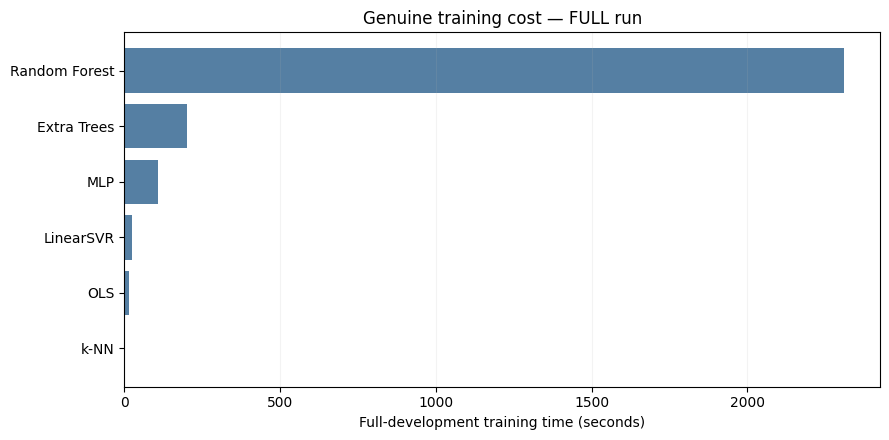

Training artifacts checksum-verified: 6


In [23]:
# 8.1.2 — Fit time chart from the current clean execution.
fig,ax=plt.subplots(figsize=(9,4.5))
d=train_metrics.sort_values('Fit_s',ascending=True)
ax.barh(d.Model,d.Fit_s,color='#557fa3')
ax.set(xlabel='Full-development training time (seconds)' if RUN_MODE=='full' else 'Smoke training time (seconds)',
       title=f'Genuine training cost — {RUN_MODE.upper()} run')
ax.grid(axis='x',alpha=.15)
fig.tight_layout();fig.savefig(FIG_DIR/'08_training_times.png',dpi=160,bbox_inches='tight');plt.show()
print('Training artifacts checksum-verified:',len(train_metrics))


## 8. Held-out inference and metric calculation


<a id="s-8-1"></a>

### 8.1. Fixed held-out prediction and checkpoint identity

**Research trace:** RQ1, RQ2, RQ3. Actual source mapping and output register: `docs/EXPERIMENT_REGISTER.md`, final section 8.1.


#### 8.1.1. Purpose

Compute predictions after all six full-development fits have completed, keeping every profile/row traceable.


#### 8.1.2. Mathematical basis and assumptions

The original final protocol processes all 275,618 held-out rows per model. k-NN uses batches of 64; other models use batches of 4,096. Batching changes the workload partition, not the selected estimator.


#### 8.1.3. Implementation and parameter choices

Retain the original model/profile inference loop, profile-reset features and batching. Each NPZ records source_row, model, profile, run mode, model-artifact SHA-256 and selection-manifest SHA-256.


#### 8.1.4. Results and verification evidence

Six models × fourteen profiles produces 84 checkpoints. Inference timing includes feature construction, predictions and compressed output writes; it is not pure predict-only latency.


#### 8.1.5. Interpretation and limitations

No prediction checkpoint selects or refines a parameter. Loaded joblib files are only the models just fitted in this trusted project run.


In [24]:
# 9.1.1 — Reproducible 84 model-profile inference checkpoints.
INFERENCE_TIMES=[]
for name in TRAIN_ORDER:
    path=MODELS_DIR/(name.replace(' ','_').replace('-','')+'.joblib')
    assert path.is_file()
    bundle=joblib.load(path)
    assert bundle['train_rows']==(1_055_198 if RUN_MODE=='full' else 6_600)
    spans=bundle['spans'];expected_names=feature_names(spans)
    assert bundle['feature_names']==expected_names
    model_start=time.perf_counter();count=0
    model_sha=sha256_file(path)
    target_dir=PRED_DIR/(name.replace(' ','_').replace('-',''))
    target_dir.mkdir(parents=True,exist_ok=True)
    for pid,profile in relevant_profiles(full_test,is_test=True):
        dest=target_dir/f'profile_{pid:03d}.npz'
        rows=profile.index.to_numpy(dtype=np.int64)
        Xtest=feature_frame(profile,spans)[expected_names].to_numpy(dtype=np.float64)
        prediction=np.empty(len(Xtest),dtype=np.float64)
        chunk=64 if name=='k-NN' else 4096
        for k in range(0,len(Xtest),chunk):
            xi=Xtest[k:k+chunk]
            if name=='OLS': prediction[k:k+chunk]=bundle['intercept']+xi@bundle['coef']
            else: prediction[k:k+chunk]=bundle['pipeline'].predict(xi)
        assert np.isfinite(prediction).all() and len(prediction)==len(rows)
        np.savez_compressed(dest,model=name,profile_id=int(pid),source_row=rows,prediction=prediction,
            mode=RUN_MODE,artifact_sha256=model_sha,selection_manifest_sha256=DEVELOPMENT_MANIFEST['manifest_sha256'])
        count+=1
        del Xtest,prediction
    assert count==14
    elapsed=time.perf_counter()-model_start
    INFERENCE_TIMES.append({'Model':name,'Inference_Loop_s':elapsed,'Profiles':count,'Mode':RUN_MODE})
    print('PASS:',name,'|',count,'original test profiles |',round(elapsed,2),'s')
    del bundle;gc.collect()
inference_metrics=pd.DataFrame(INFERENCE_TIMES)
inference_metrics.to_csv(RESULTS_DIR/'inference_times.csv',index=False)
assert len(list(PRED_DIR.glob('*/*.npz')))==84
print('PASS: 84 saved prediction files; test observations never entered model fitting.')


PASS: OLS | 14 original test profiles | 1.63 s
PASS: k-NN | 14 original test profiles | 4929.14 s
PASS: Extra Trees | 14 original test profiles | 12.57 s
PASS: MLP | 14 original test profiles | 2.36 s
PASS: Random Forest | 14 original test profiles | 9.99 s
PASS: LinearSVR | 14 original test profiles | 2.17 s
PASS: 84 saved prediction files; test observations never entered model fitting.


<a id="s-8-2"></a>

### 8.2. Pooled and per-profile metric definitions

**Research trace:** RQ2, RQ3, RQ4. Actual source mapping and output register: `docs/EXPERIMENT_REGISTER.md`, final section 8.2.


#### 8.2.1. Purpose

Calculate all errors from source-aligned predictions and original measured magnet temperatures.


#### 8.2.2. Mathematical basis and assumptions

With $e_i=\hat T_i-T_i$, $MSE=N^{-1}\sum e_i^2$ (°C²), $RMSE=\sqrt{MSE}$ (°C), $MAE=N^{-1}\sum|e_i|$ (°C), and $bias=N^{-1}\sum e_i$ (°C). $R^2=1-\sum e_i^2/\sum(T_i-\bar T)^2$ is dimensionless. Positive bias means overprediction. Pooled metrics weight each observation equally; macro RMSE averages the 14 profile RMSEs equally. Worst-profile RMSE is their maximum.


#### 8.2.3. Implementation and parameter choices

Retain the original score function, original row-alignment assertions and pooled/profile aggregation. Model identity, artifact hash and manifest identity are checked before a checkpoint is used.


#### 8.2.4. Results and verification evidence

profile_metrics.csv has 84 records and overall_metrics.csv six. Tests compare metrics with independent calculations, exercise invalid inputs and check the bias/variance identity.


#### 8.2.5. Interpretation and limitations

Pooled error can hide poor sessions. R² may be negative and depends on target variation. None of these point metrics alone quantifies calibrated uncertainty or rare-event safety.


In [25]:
# 10.1.1 — Derive 84 profile metrics and six pooled metrics from saved predictions.
from pmsm_project.metrics import score
profile_rows=[];pooled_rows=[]
profile_lookup={pid:p for pid,p in relevant_profiles(full_test,is_test=True)}
for name in TRAIN_ORDER:
    yy=[];yp=[];summaries=[]
    model_dir=PRED_DIR/(name.replace(' ','_').replace('-',''))
    for pid,profile in profile_lookup.items():
        path=model_dir/f'profile_{pid:03d}.npz'
        from pmsm_project.checkpoints import load_prediction_checkpoint
        expected_artifact=train_metrics.set_index('Model').loc[name,'Artifact_SHA256']
        pred=load_prediction_checkpoint(path,model=name,profile_id=pid,
            source_rows=profile.index.to_numpy(dtype=np.int64),mode=RUN_MODE,
            artifact_sha256=expected_artifact,
            manifest_sha256=DEVELOPMENT_MANIFEST['manifest_sha256'])
        actual=profile.pm.to_numpy(dtype=np.float64)
        met=score(actual,pred)
        profile_rows.append({'Model':name,'Profile_ID':pid,'Observations':len(actual),**met})
        summaries.append(met);yy.append(actual);yp.append(pred)
    combined=score(np.concatenate(yy),np.concatenate(yp))
    pooled_rows.append({'Model':name,'Observations':sum(len(y) for y in yy),**combined,
       'Macro_RMSE_C':float(np.mean([m['RMSE_C'] for m in summaries])),
       'Worst_Profile_RMSE_C':float(max(m['RMSE_C'] for m in summaries))})
profile_metrics=pd.DataFrame(profile_rows)
overall_metrics=pd.DataFrame(pooled_rows).sort_values('RMSE_C').reset_index(drop=True)
assert len(profile_metrics)==84 and len(overall_metrics)==6
assert overall_metrics.Observations.eq(275_618 if RUN_MODE=='full' else 14*160).all()
profile_metrics.to_csv(RESULTS_DIR/'profile_metrics.csv',index=False)
overall_metrics.to_csv(RESULTS_DIR/'overall_metrics.csv',index=False)
print('Final held-out results' if RUN_MODE=='full' else 'SMOKE-ONLY scores (NOT research findings)')
display(overall_metrics[['Model','RMSE_C','MAE_C','R2','Bias_C','Worst_Profile_RMSE_C']].round(4))


Final held-out results


,Model,RMSE_C,MAE_C,R2,Bias_C,Worst_Profile_RMSE_C
0,MLP,4.3627,3.2879,0.9547,-0.4890,6.6995
1,LinearSVR,5.6653,3.6893,0.9236,0.4580,11.1839
2,Random Forest,5.7651,4.5125,0.9209,-1.4511,9.4252
3,OLS,5.9672,4.5709,0.9152,0.0474,8.8412
4,Extra Trees,6.1654,4.6565,0.9095,-1.5042,10.1649
5,k-NN,9.0770,6.4580,0.8039,-1.2630,14.6047


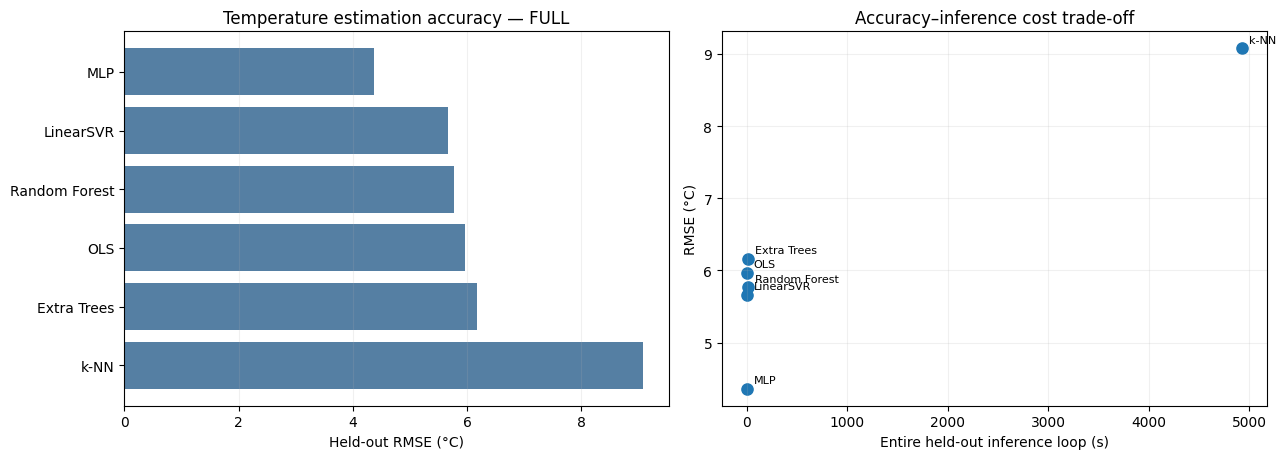

In [26]:
# 10.2.1 — Accuracy bars and prediction-cost scatter using newly recomputed metrics.
merged=overall_metrics.merge(inference_metrics,on='Model').merge(train_metrics[['Model','Fit_s']],on='Model')
fig,axes=plt.subplots(1,2,figsize=(13,4.7))
d=merged.sort_values('RMSE_C',ascending=False)
axes[0].barh(d.Model,d.RMSE_C,color='#557fa3')
axes[0].set(xlabel='Held-out RMSE (°C)',title=f'Temperature estimation accuracy — {RUN_MODE.upper()}')
axes[0].grid(axis='x',alpha=.18)
axes[1].scatter(merged.Inference_Loop_s,merged.RMSE_C,s=65)
for r in merged.itertuples():axes[1].annotate(r.Model,(r.Inference_Loop_s,r.RMSE_C),xytext=(5,4),textcoords='offset points',fontsize=8)
axes[1].set(xlabel='Entire held-out inference loop (s)',ylabel='RMSE (°C)',title='Accuracy–inference cost trade-off')
axes[1].grid(alpha=.18);fig.tight_layout()
fig.savefig(FIG_DIR/'10_accuracy_and_cost.png',dpi=160,bbox_inches='tight');plt.show()


## 9. Model-specific final evaluation

These read-only summaries use the exact pooled/profile tables already computed in Chapter 8. They do not retrain, tune, alter rankings or generate alternative predictions.


<a id="s-9-1"></a>

### 9.1. OLS final evidence

**Research trace:** RQ2, RQ3, RQ4.


#### 9.1.1. Purpose

Interpret OLS using its actual freshly executed final outputs.


#### 9.1.2. Mathematical basis and assumptions

OLS predicts $\hat T=b+x^T\beta$ and minimises $\sum_i(T_i-b-x_i^T\beta)^2$. The final fit uses profile-wise augmented QR compression, development-only feature moments and the original `gelsd` rank-aware least-squares solve. The intercept is unpenalised. OLS is linear in 108 nonlinear/history-derived inputs, not necessarily linear in raw operating conditions [SCIPY].


#### 9.1.3. Implementation and parameter choices

Filter overall_metrics, profile_metrics, train_metrics and inference_metrics for 'OLS'. The row selections below only present previously computed evidence. The fitted algorithm is specified in section 6.1.


#### 9.1.4. Results and verification evidence

The displayed tables contain pooled metrics, 14 profile errors, measured fit cost and inference-loop cost. Source-row/model/manifest identities are preserved by the preceding inference stage.


#### 9.1.5. Interpretation and limitations

Assess pooled accuracy together with the worst session, signed bias, convergence status and cost. Differences from archived scores are outcomes of fresh selected settings and software/hardware behaviour, not a requirement to force a historical result.


In [27]:
model_name='OLS'
display(overall_metrics.loc[overall_metrics.Model.eq(model_name)])
display(train_metrics.loc[train_metrics.Model.eq(model_name)])
display(inference_metrics.loc[inference_metrics.Model.eq(model_name)])
display(profile_metrics.loc[profile_metrics.Model.eq(model_name), ["Profile_ID", "RMSE_C", "MAE_C", "Bias_C", "R2"]])


,Model,Observations,MSE_C2,RMSE_C,MAE_C,R2,Bias_C,P95_AE_C,Max_AE_C,Macro_RMSE_C,Worst_Profile_RMSE_C
3,OLS,275618,35.607691,5.967218,4.57092,0.915232,0.04741,11.448476,43.420755,6.056995,8.841188


,Model,Train_Rows,Train_Profiles,Fit_s,Convergence_Warnings,Model_File,Artifact_SHA256,Mode,Development_Run_ID,Selection_Manifest_SHA256
3,OLS,1055198,55,15.678001,0,/content/MMA3001_Connected_Project/MMA3001_PMS...,22732bd16cfc9b042efeb9b6cb5df9d7ee37ff41a77624...,full,d9ae4c0a-aa9f-4400-9e2a-88d11f3bfe36,57a55568b5abae9c9dc89596d14883b56f44b2ecf55bfe...


,Model,Inference_Loop_s,Profiles,Mode
0,OLS,1.625301,14,full


,Profile_ID,RMSE_C,MAE_C,Bias_C,R2
0,23,8.841188,4.760938,3.817131,0.831166
1,13,5.525166,4.936150,4.936150,-1.762038
2,29,5.439812,4.742501,-3.672826,0.908473
3,24,8.002272,6.509704,4.994913,0.881912
4,16,5.470302,4.358034,-1.720255,0.324742
5,53,3.264192,2.764723,-2.508771,0.829854
6,56,7.807689,6.280027,-4.720379,0.495372
7,62,5.091326,4.441676,-3.399408,0.862786
8,47,7.384256,6.593896,-5.850095,-17.282881
9,42,4.140117,3.229775,0.616865,0.879168


<a id="s-9-2"></a>

### 9.2. k-NN final evidence

**Research trace:** RQ2, RQ3, RQ4.


#### 9.2.1. Purpose

Interpret k-NN using its actual freshly executed final outputs.


#### 9.2.2. Mathematical basis and assumptions

For the $k$ nearest standardised training states $\mathcal N_k(x)$, $\hat z(x)=\sum_{i\in\mathcal N_k}w_i z_i/\sum_iw_i$. Uniform weights have $w_i=1$; distance weights follow scikit-learn’s inverse-distance convention, including its zero-distance handling. $z=(T-\mu_T)/\sigma_T$ uses development/fold fitting statistics. Standardisation is essential because volts, amperes and rpm otherwise contribute incompatible Euclidean scales [SKLEARN].


#### 9.2.3. Implementation and parameter choices

Filter overall_metrics, profile_metrics, train_metrics and inference_metrics for 'k-NN'. The row selections below only present previously computed evidence. The fitted algorithm is specified in section 6.2.


#### 9.2.4. Results and verification evidence

The displayed tables contain pooled metrics, 14 profile errors, measured fit cost and inference-loop cost. Source-row/model/manifest identities are preserved by the preceding inference stage.


#### 9.2.5. Interpretation and limitations

Assess pooled accuracy together with the worst session, signed bias, convergence status and cost. Differences from archived scores are outcomes of fresh selected settings and software/hardware behaviour, not a requirement to force a historical result.


In [28]:
model_name='k-NN'
display(overall_metrics.loc[overall_metrics.Model.eq(model_name)])
display(train_metrics.loc[train_metrics.Model.eq(model_name)])
display(inference_metrics.loc[inference_metrics.Model.eq(model_name)])
display(profile_metrics.loc[profile_metrics.Model.eq(model_name), ["Profile_ID", "RMSE_C", "MAE_C", "Bias_C", "R2"]])


,Model,Observations,MSE_C2,RMSE_C,MAE_C,R2,Bias_C,P95_AE_C,Max_AE_C,Macro_RMSE_C,Worst_Profile_RMSE_C
5,k-NN,275618,82.391707,9.076988,6.45797,0.803857,-1.263043,20.827348,47.072189,8.749314,14.604716


,Model,Train_Rows,Train_Profiles,Fit_s,Convergence_Warnings,Model_File,Artifact_SHA256,Mode,Development_Run_ID,Selection_Manifest_SHA256
5,k-NN,1055198,55,2.401384,0,/content/MMA3001_Connected_Project/MMA3001_PMS...,29061becfaa34c69dfc19e62ead08c43d16fcc8d5dceae...,full,d9ae4c0a-aa9f-4400-9e2a-88d11f3bfe36,57a55568b5abae9c9dc89596d14883b56f44b2ecf55bfe...


,Model,Inference_Loop_s,Profiles,Mode
1,k-NN,4929.136934,14,full


,Profile_ID,RMSE_C,MAE_C,Bias_C,R2
14,23,5.871759,3.609209,1.401450,0.925531
15,13,2.050177,1.552809,-0.420443,0.619704
16,29,9.691289,7.332147,-2.602277,0.709502
17,24,14.604716,12.771800,-11.160587,0.606664
18,16,4.969140,4.274452,-3.877401,0.442802
19,53,6.587577,5.106199,-0.469617,0.307017
20,56,14.318964,11.040790,-7.923412,-0.697264
21,62,6.225048,4.809873,-0.962760,0.794873
22,47,11.892755,8.695601,-4.196721,-46.423773
23,42,11.002025,8.271019,3.675491,0.146697


<a id="s-9-3"></a>

### 9.3. Extra Trees final evidence

**Research trace:** RQ2, RQ3, RQ4.


#### 9.3.1. Purpose

Interpret Extra Trees using its actual freshly executed final outputs.


#### 9.3.2. Mathematical basis and assumptions

Extra Trees averages $B$ regression trees, $\hat z=B^{-1}\sum_bh_b(x)$. Random candidate thresholds introduce additional split randomness compared with the Random Forest implementation [GEURTS06]. The same original tree-count, depth, leaf-size, split-size and bootstrap dimensions are searched. `max_features='sqrt'`, seed 42 and two workers remain fixed; the algorithm is not substituted with a differently configured forest.


#### 9.3.3. Implementation and parameter choices

Filter overall_metrics, profile_metrics, train_metrics and inference_metrics for 'Extra Trees'. The row selections below only present previously computed evidence. The fitted algorithm is specified in section 6.3.


#### 9.3.4. Results and verification evidence

The displayed tables contain pooled metrics, 14 profile errors, measured fit cost and inference-loop cost. Source-row/model/manifest identities are preserved by the preceding inference stage.


#### 9.3.5. Interpretation and limitations

Assess pooled accuracy together with the worst session, signed bias, convergence status and cost. Differences from archived scores are outcomes of fresh selected settings and software/hardware behaviour, not a requirement to force a historical result.


In [29]:
model_name='Extra Trees'
display(overall_metrics.loc[overall_metrics.Model.eq(model_name)])
display(train_metrics.loc[train_metrics.Model.eq(model_name)])
display(inference_metrics.loc[inference_metrics.Model.eq(model_name)])
display(profile_metrics.loc[profile_metrics.Model.eq(model_name), ["Profile_ID", "RMSE_C", "MAE_C", "Bias_C", "R2"]])


,Model,Observations,MSE_C2,RMSE_C,MAE_C,R2,Bias_C,P95_AE_C,Max_AE_C,Macro_RMSE_C,Worst_Profile_RMSE_C
4,Extra Trees,275618,38.012096,6.165395,4.65648,0.909508,-1.504223,12.9768,31.721349,6.274654,10.164886


,Model,Train_Rows,Train_Profiles,Fit_s,Convergence_Warnings,Model_File,Artifact_SHA256,Mode,Development_Run_ID,Selection_Manifest_SHA256
4,Extra Trees,1055198,55,201.50912,0,/content/MMA3001_Connected_Project/MMA3001_PMS...,06dae361d741316bec6e5f5f4648af75ee96a186d961cf...,full,d9ae4c0a-aa9f-4400-9e2a-88d11f3bfe36,57a55568b5abae9c9dc89596d14883b56f44b2ecf55bfe...


,Model,Inference_Loop_s,Profiles,Mode
2,Extra Trees,12.567049,14,full


,Profile_ID,RMSE_C,MAE_C,Bias_C,R2
28,23,4.205197,2.737695,-0.259900,0.961805
29,13,2.850302,2.593579,2.593579,0.264943
30,29,7.750339,6.491138,-5.978965,0.814210
31,24,10.164886,8.155414,-6.600000,0.809461
32,16,6.178632,5.220055,-4.439265,0.138547
33,53,2.351799,1.910494,0.856242,0.911677
34,56,9.222775,8.196527,-8.068968,0.295875
35,62,3.572999,2.491557,-1.414997,0.932422
36,47,10.061785,9.243200,-9.243200,-32.945421
37,42,5.120783,4.420405,0.868009,0.815145


<a id="s-9-4"></a>

### 9.4. MLP final evidence

**Research trace:** RQ2, RQ3, RQ4.


#### 9.4.1. Purpose

Interpret MLP using its actual freshly executed final outputs.


#### 9.4.2. Mathematical basis and assumptions

For hidden layer $\ell$, $h^{(\ell)}=\max(0,W^{(\ell)}h^{(\ell-1)}+b^{(\ell)})$ and the output layer is linear. Adam adjusts weights using gradients of squared prediction loss plus the implementation’s L2 penalty controlled by $\alpha$ [KINGMA15,SKLEARN]. Equal hidden-layer widths are $(n_{units},)\times n_{layers}$. Input and target scaling improves numerical conditioning; it does not establish physical validity.


#### 9.4.3. Implementation and parameter choices

Filter overall_metrics, profile_metrics, train_metrics and inference_metrics for 'MLP'. The row selections below only present previously computed evidence. The fitted algorithm is specified in section 6.4.


#### 9.4.4. Results and verification evidence

The displayed tables contain pooled metrics, 14 profile errors, measured fit cost and inference-loop cost. Source-row/model/manifest identities are preserved by the preceding inference stage.


#### 9.4.5. Interpretation and limitations

Assess pooled accuracy together with the worst session, signed bias, convergence status and cost. Differences from archived scores are outcomes of fresh selected settings and software/hardware behaviour, not a requirement to force a historical result.


In [30]:
model_name='MLP'
display(overall_metrics.loc[overall_metrics.Model.eq(model_name)])
display(train_metrics.loc[train_metrics.Model.eq(model_name)])
display(inference_metrics.loc[inference_metrics.Model.eq(model_name)])
display(profile_metrics.loc[profile_metrics.Model.eq(model_name), ["Profile_ID", "RMSE_C", "MAE_C", "Bias_C", "R2"]])


,Model,Observations,MSE_C2,RMSE_C,MAE_C,R2,Bias_C,P95_AE_C,Max_AE_C,Macro_RMSE_C,Worst_Profile_RMSE_C
0,MLP,275618,19.033067,4.36269,3.287912,0.95469,-0.489021,8.857042,33.190905,4.267815,6.699457


,Model,Train_Rows,Train_Profiles,Fit_s,Convergence_Warnings,Model_File,Artifact_SHA256,Mode,Development_Run_ID,Selection_Manifest_SHA256
0,MLP,1055198,55,109.382788,0,/content/MMA3001_Connected_Project/MMA3001_PMS...,d589f529573706c26f1198a11e8640b95a14a95c379d01...,full,d9ae4c0a-aa9f-4400-9e2a-88d11f3bfe36,57a55568b5abae9c9dc89596d14883b56f44b2ecf55bfe...


,Model,Inference_Loop_s,Profiles,Mode
3,MLP,2.359771,14,full


,Profile_ID,RMSE_C,MAE_C,Bias_C,R2
42,23,4.191528,2.794666,2.562085,0.962052
43,13,3.336362,2.881945,2.881945,-0.007129
44,29,6.699457,5.012397,-1.768088,0.861178
45,24,2.716788,2.345640,2.336774,0.986389
46,16,3.263883,2.496014,0.238110,0.759610
47,53,5.690042,4.480415,-4.382958,0.482986
48,56,4.717709,3.859085,-2.501319,0.815758
49,62,2.383027,1.948304,-0.736391,0.969940
50,47,6.290052,5.393868,-5.206405,-12.265990
51,42,5.272248,4.028534,-0.492864,0.804048


<a id="s-9-5"></a>

### 9.5. Random Forest final evidence

**Research trace:** RQ2, RQ3, RQ4.


#### 9.5.1. Purpose

Interpret Random Forest using its actual freshly executed final outputs.


#### 9.5.2. Mathematical basis and assumptions

A regression tree partitions feature space into leaves and predicts each leaf’s mean target. Splits seek reductions in squared error. A forest averages $B$ tree predictions, $\hat z=B^{-1}\sum_{b=1}^B h_b(x)$. Bootstrap sampling and random feature subsets reduce correlation between trees [BREIMAN01]. The supplied model retains `max_features='sqrt'`, seed 42 and two workers; `bootstrap` remains an optimised yes/no choice.


#### 9.5.3. Implementation and parameter choices

Filter overall_metrics, profile_metrics, train_metrics and inference_metrics for 'Random Forest'. The row selections below only present previously computed evidence. The fitted algorithm is specified in section 6.5.


#### 9.5.4. Results and verification evidence

The displayed tables contain pooled metrics, 14 profile errors, measured fit cost and inference-loop cost. Source-row/model/manifest identities are preserved by the preceding inference stage.


#### 9.5.5. Interpretation and limitations

Assess pooled accuracy together with the worst session, signed bias, convergence status and cost. Differences from archived scores are outcomes of fresh selected settings and software/hardware behaviour, not a requirement to force a historical result.


In [31]:
model_name='Random Forest'
display(overall_metrics.loc[overall_metrics.Model.eq(model_name)])
display(train_metrics.loc[train_metrics.Model.eq(model_name)])
display(inference_metrics.loc[inference_metrics.Model.eq(model_name)])
display(profile_metrics.loc[profile_metrics.Model.eq(model_name), ["Profile_ID", "RMSE_C", "MAE_C", "Bias_C", "R2"]])


,Model,Observations,MSE_C2,RMSE_C,MAE_C,R2,Bias_C,P95_AE_C,Max_AE_C,Macro_RMSE_C,Worst_Profile_RMSE_C
2,Random Forest,275618,33.235856,5.765055,4.512507,0.920878,-1.451146,10.695342,33.042302,5.815305,9.425182


,Model,Train_Rows,Train_Profiles,Fit_s,Convergence_Warnings,Model_File,Artifact_SHA256,Mode,Development_Run_ID,Selection_Manifest_SHA256
2,Random Forest,1055198,55,2310.405774,0,/content/MMA3001_Connected_Project/MMA3001_PMS...,7542bdc542051882efd8254ed5aa5f59c76f46373f434c...,full,d9ae4c0a-aa9f-4400-9e2a-88d11f3bfe36,57a55568b5abae9c9dc89596d14883b56f44b2ecf55bfe...


,Model,Inference_Loop_s,Profiles,Mode
4,Random Forest,9.986081,14,full


,Profile_ID,RMSE_C,MAE_C,Bias_C,R2
56,23,4.583377,3.034861,0.168708,0.954626
57,13,4.392015,4.351665,4.351665,-0.745286
58,29,6.842228,5.890241,-5.163795,0.855198
59,24,6.631859,5.129464,-3.438368,0.918895
60,16,6.240132,5.250070,-4.558263,0.121312
61,53,2.155604,1.746635,0.066341,0.925799
62,56,9.035371,7.673844,-7.291807,0.324200
63,62,3.960160,3.183804,-1.343890,0.916984
64,47,9.425182,8.961217,-8.961217,-28.785892
65,42,4.036089,3.359101,1.074414,0.885164


<a id="s-9-6"></a>

### 9.6. LinearSVR final evidence

**Research trace:** RQ2, RQ3, RQ4.


#### 9.6.1. Purpose

Interpret LinearSVR using its actual freshly executed final outputs.


#### 9.6.2. Mathematical basis and assumptions

Direct LinearSVR uses $f(x)=w^Tx+b$ with $\frac12\|w\|^2+C\sum_i\max(0,|z_i-f(x_i)|-\epsilon)$, subject to LIBLINEAR’s intercept-regularisation convention [FAN08,SKLEARN]. It removes the nonlinear kernel. The final configuration keeps `loss='epsilon_insensitive'`, `dual=True`, `tol=1e-4`, `max_iter=10000` and seed 42. The inherited $\epsilon$ and spans originate in the fresh larger RBF search; Stage 9 selects the reference $C$.


#### 9.6.3. Implementation and parameter choices

Filter overall_metrics, profile_metrics, train_metrics and inference_metrics for 'LinearSVR'. The row selections below only present previously computed evidence. The fitted algorithm is specified in section 6.6.


#### 9.6.4. Results and verification evidence

The displayed tables contain pooled metrics, 14 profile errors, measured fit cost and inference-loop cost. Source-row/model/manifest identities are preserved by the preceding inference stage.


#### 9.6.5. Interpretation and limitations

Assess pooled accuracy together with the worst session, signed bias, convergence status and cost. Differences from archived scores are outcomes of fresh selected settings and software/hardware behaviour, not a requirement to force a historical result.


In [32]:
model_name='LinearSVR'
display(overall_metrics.loc[overall_metrics.Model.eq(model_name)])
display(train_metrics.loc[train_metrics.Model.eq(model_name)])
display(inference_metrics.loc[inference_metrics.Model.eq(model_name)])
display(profile_metrics.loc[profile_metrics.Model.eq(model_name), ["Profile_ID", "RMSE_C", "MAE_C", "Bias_C", "R2"]])


,Model,Observations,MSE_C2,RMSE_C,MAE_C,R2,Bias_C,P95_AE_C,Max_AE_C,Macro_RMSE_C,Worst_Profile_RMSE_C
1,LinearSVR,275618,32.095466,5.665286,3.689324,0.923593,0.458012,10.422498,44.319016,6.100806,11.183897


,Model,Train_Rows,Train_Profiles,Fit_s,Convergence_Warnings,Model_File,Artifact_SHA256,Mode,Development_Run_ID,Selection_Manifest_SHA256
1,LinearSVR,1055198,55,25.887238,0,/content/MMA3001_Connected_Project/MMA3001_PMS...,dcc1bcb65205f02c61d6aa5ad7baf55242a0d0f606d07e...,full,d9ae4c0a-aa9f-4400-9e2a-88d11f3bfe36,57a55568b5abae9c9dc89596d14883b56f44b2ecf55bfe...


,Model,Inference_Loop_s,Profiles,Mode
5,LinearSVR,2.166333,14,full


,Profile_ID,RMSE_C,MAE_C,Bias_C,R2
70,23,11.183897,5.523098,4.944570,0.729837
71,13,3.714118,2.674187,2.673533,-0.248103
72,29,4.856395,3.894425,-2.147059,0.927053
73,24,9.281629,5.658486,5.464046,0.841136
74,16,5.125183,3.776485,-0.650627,0.407258
75,53,3.550074,3.091909,-2.637385,0.798745
76,56,5.563029,4.544605,-3.494498,0.743818
77,62,3.832668,2.526797,-0.864164,0.922243
78,47,7.649812,6.995844,-4.306729,-18.621520
79,42,4.549834,3.121448,0.111554,0.854068


## 10. Generalisation, bias and temperature histories


<a id="s-10-1"></a>

### 10.1. Session-level RMSE and signed bias

**Research trace:** RQ2, RQ3, RQ4. Actual source mapping and output register: `docs/EXPERIMENT_REGISTER.md`, final section 10.1.


#### 10.1.1. Purpose

Expose generalisation differences between recording sessions that pooled metrics can hide.


#### 10.1.2. Mathematical basis and assumptions

The heatmaps place one model/profile metric in each of 14×6 cells. Signed bias retains direction; absolute bias would hide whether a model underpredicts potentially important high temperatures.


#### 10.1.3. Implementation and parameter choices

Retain the original pivots, colour normalisation, annotations and profile ordering. The charts are descriptive diagnostics of the fixed final evaluation.


#### 10.1.4. Results and verification evidence

Saved RMSE and bias heatmaps link directly to profile_metrics.csv. Units and sign conventions appear on axes/colour bars.


#### 10.1.5. Interpretation and limitations

Use these patterns to discuss limitations, not to choose a replacement parameter after examining the test set. Any later development requires a separately disclosed new evaluation design.


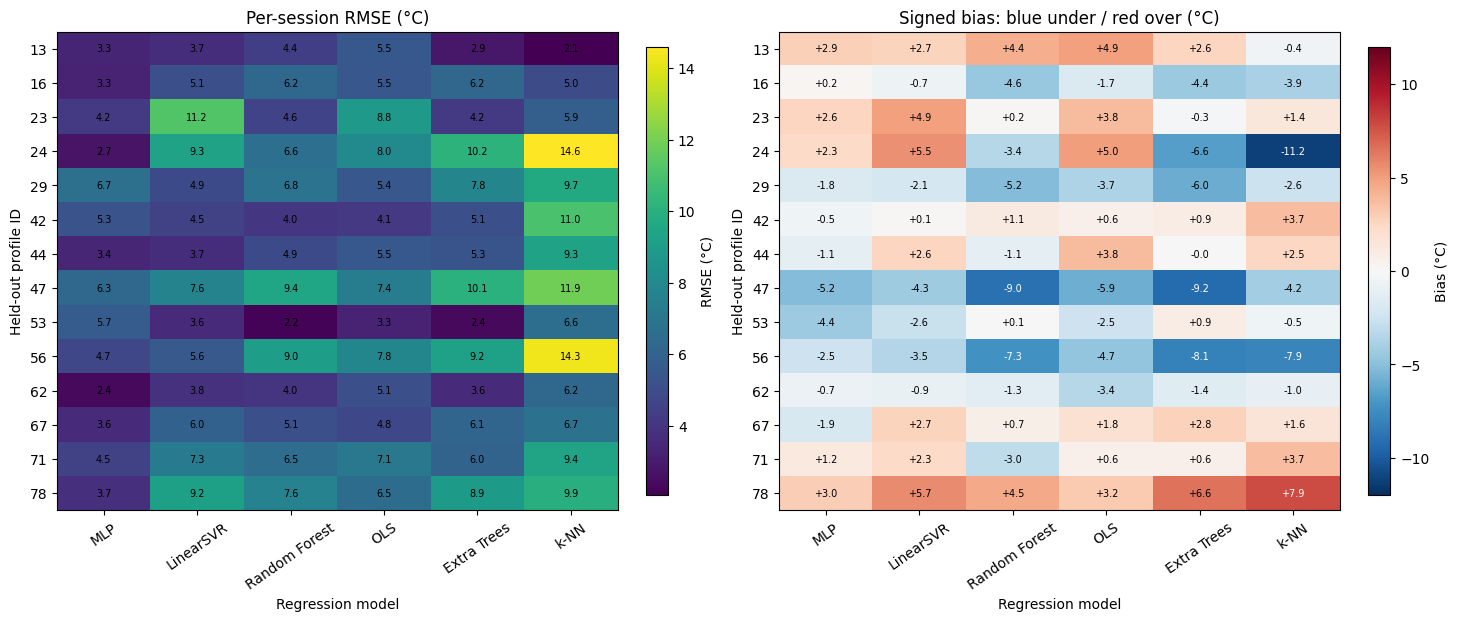

In [33]:
# 11.2.1 — Paired RMSE and signed-bias heatmaps, 14 recordings × 6 models.
from matplotlib.colors import TwoSlopeNorm
mx=profile_metrics.pivot(index='Profile_ID',columns='Model',values='RMSE_C').loc[:,REPORT_ORDER].sort_index()
bx=profile_metrics.pivot(index='Profile_ID',columns='Model',values='Bias_C').loc[:,REPORT_ORDER].sort_index()
fig,axs=plt.subplots(1,2,figsize=(14.5,6.1),constrained_layout=True)
a=axs[0].imshow(mx.to_numpy(),cmap='viridis',aspect='auto')
cap=max(1,float(np.ceil(np.max(np.abs(bx.to_numpy())))))
b=axs[1].imshow(bx.to_numpy(),cmap='RdBu_r',norm=TwoSlopeNorm(vmin=-cap,vcenter=0,vmax=cap),aspect='auto')
for ax,z,title in [(axs[0],mx,'Per-session RMSE (°C)'),(axs[1],bx,'Signed bias: blue under / red over (°C)')]:
    ax.set(xticks=range(6),xticklabels=REPORT_ORDER,yticks=range(14),yticklabels=mx.index,
           xlabel='Regression model',ylabel='Held-out profile ID',title=title)
    ax.tick_params(axis='x',rotation=35)
    for i in range(z.shape[0]):
        for j in range(z.shape[1]):
            val=z.iat[i,j]
            ax.text(j,i,f'{val:+.1f}' if ax is axs[1] else f'{val:.1f}',ha='center',va='center',fontsize=7,
                    color='white' if (ax is axs[1] and abs(val)>cap*.55) else 'black')
fig.colorbar(a,ax=axs[0],fraction=.04,label='RMSE (°C)')
fig.colorbar(b,ax=axs[1],fraction=.04,label='Bias (°C)')
fig.savefig(FIG_DIR/'11_profile_rmse_bias_heatmaps.png',dpi=170,bbox_inches='tight');plt.show()


<a id="s-10-2"></a>

### 10.2. Bias–variance error decomposition

**Research trace:** RQ4. Actual source mapping and output register: `docs/EXPERIMENT_REGISTER.md`, final section 10.2.


#### 10.2.1. Purpose

Distinguish systematic session offsets from time-varying prediction error.


#### 10.2.2. Mathematical basis and assumptions

Using a population divisor N, $MSE=bias^2+N^{-1}\sum_i(e_i-bias)^2$. Thus $100\,bias^2/MSE$ is the percentage of MSE attributable to a constant offset when MSE>0. It is not the percentage of predictions that are biased.


#### 10.2.3. Implementation and parameter choices

Retain the original calculation, zero-error handling, numerical nonnegative clipping and ten-largest-absolute-bias display. Unit tests check the mathematical identity independently.


#### 10.2.4. Results and verification evidence

profile_bias_diagnostics.csv and the decomposition figure make the session-level offsets interpretable.


#### 10.2.5. Interpretation and limitations

Subtracting the observed test bias would be target-informed recalibration. This stage diagnoses error and does not modify any final prediction.


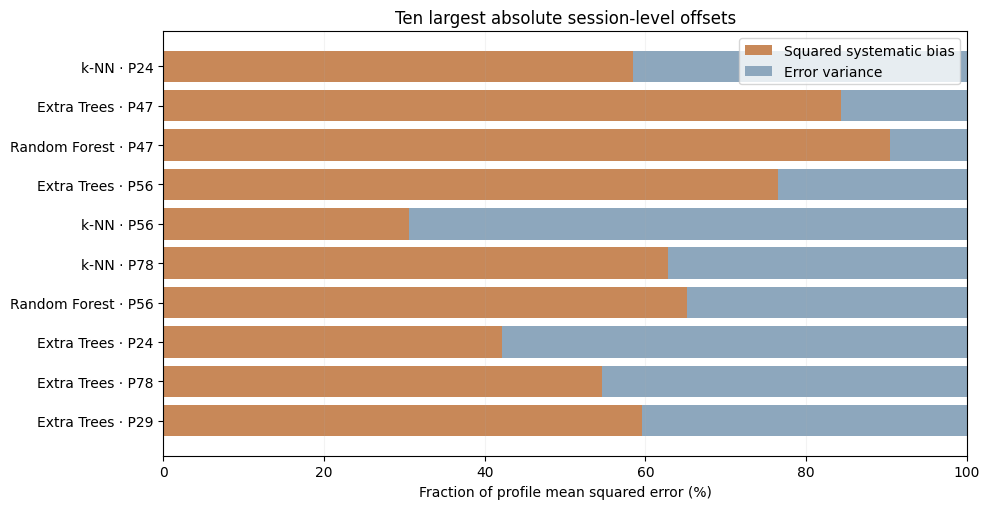

In [34]:
# 11.3.1 — Visual bias decomposition and high-bias examples.
diag=profile_metrics.copy()
diag['Absolute_Bias_C']=diag.Bias_C.abs()
diag['Bias_Contribution_Pct']=np.where(diag.RMSE_C>0,100*diag.Bias_C**2/diag.RMSE_C**2,0.0)
diag['Error_Variance_C2']=np.maximum(diag.RMSE_C**2-diag.Bias_C**2,0.)
assert diag.Bias_Contribution_Pct.between(0,100+1e-6).all()
worst=diag.nlargest(10,'Absolute_Bias_C').iloc[::-1].copy()
worst['Label']=worst.Model+' · P'+worst.Profile_ID.astype(str)
fig,ax=plt.subplots(figsize=(10,5.2))
ax.barh(worst.Label,worst.Bias_Contribution_Pct,color='#c88858',label='Squared systematic bias')
ax.barh(worst.Label,100-worst.Bias_Contribution_Pct,left=worst.Bias_Contribution_Pct,color='#8da7bd',label='Error variance')
ax.set(xlim=(0,100),xlabel='Fraction of profile mean squared error (%)',title='Ten largest absolute session-level offsets');ax.legend();ax.grid(axis='x',alpha=.15)
fig.tight_layout();fig.savefig(FIG_DIR/'11_bias_decomposition.png',dpi=160,bbox_inches='tight');plt.show()
diag.to_csv(RESULTS_DIR/'profile_bias_diagnostics.csv',index=False)


<a id="s-10-3"></a>

### 10.3. Measured and predicted temperature histories

**Research trace:** RQ2, RQ3, RQ4. Actual source mapping and output register: `docs/EXPERIMENT_REGISTER.md`, final section 10.3.


#### 10.3.1. Purpose

Relate scalar errors to the engineering temperature trajectory on the longest held-out recording.


#### 10.3.2. Mathematical basis and assumptions

Elapsed minutes are row position/(2×60). The original plot decimates only the displayed lines to approximately 1,800 positions; all original rows remain in the numerical metrics.


#### 10.3.3. Implementation and parameter choices

Retain the original longest-session selection and fixed displayed model subset MLP, LinearSVR and Random Forest. Load the previously saved predictions, without re-fitting or correcting them.


#### 10.3.4. Results and verification evidence

The measured/predicted temperature figure shows offset, response lag and transient differences for this one recording, with temperature in °C and elapsed time in minutes.


#### 10.3.5. Interpretation and limitations

The fixed illustrative subset is not a post-test model-selection step. One selected recording is not representative evidence for every operating condition.


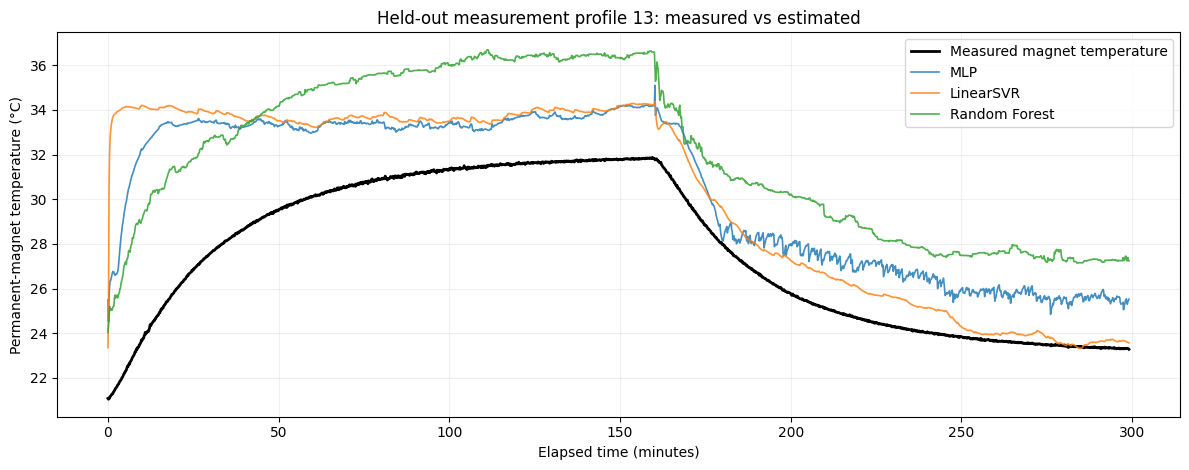

In [35]:
# 11.4.1 — Temperature history on the longest untouched session.
pid=max(profile_lookup,key=lambda j:len(profile_lookup[j]));pr=profile_lookup[pid]
time_min=np.arange(len(pr))/(FS_HZ*60)
step=max(1,len(pr)//1800)
fig,ax=plt.subplots(figsize=(12,4.8))
ax.plot(time_min[::step],pr.pm.to_numpy()[::step],color='black',lw=2,label='Measured magnet temperature')
for name in ('MLP','LinearSVR','Random Forest'):
    filename=PRED_DIR/(name.replace(' ','_').replace('-',''))/f'profile_{pid:03d}.npz'
    with np.load(filename,allow_pickle=False) as saved:pred=saved['prediction'].copy()
    ax.plot(time_min[::step],pred[::step],lw=1.2,alpha=.83,label=name)
ax.set(xlabel='Elapsed time (minutes)',ylabel='Permanent-magnet temperature (°C)',title=f'Held-out measurement profile {pid}: measured vs estimated')
ax.legend();ax.grid(alpha=.18);fig.tight_layout();fig.savefig(FIG_DIR/'11_temperature_history.png',dpi=160,bbox_inches='tight');plt.show()


## 11. Consistency audit and result export


<a id="s-11-1"></a>

### 11.1. Consistency audit, historical comparison and portable outputs

**Research trace:** RQ1–RQ4. Actual source mapping and output register: `docs/EXPERIMENT_REGISTER.md`, final section 11.1.


#### 11.1.1. Purpose

Verify the final evidence is complete and linked to the imported development run.


#### 11.1.2. Mathematical basis and assumptions

Completeness requires six model artifacts, 84 profile checkpoints, 84 profile metric rows and six pooled metrics with the original row/profile totals. Historical RMSE differences are descriptive comparisons only, not acceptance thresholds.


#### 11.1.3. Implementation and parameter choices

Retain the original final consistency/export routine, development-run identity and manifest SHA-256. Save current tables/figures separately from large models and predictions. No archived score is used in training or selection.


#### 11.1.4. Results and verification evidence

run_manifest.json, reference_comparison.csv and a portable results/figures ZIP identify what actually executed. A smoke result remains explicitly labelled and ineligible for scientific conclusions.


#### 11.1.5. Interpretation and limitations

This audit does not certify the separate written report, presentation, publication, commit history or student understanding. Those remain individual assessment responsibilities.


In [36]:
# 12.2.1 — Final consistency audit and portable results bundle.
import zipfile
assert set(train_metrics.Model)==set(SELECTED)
assert len(profile_metrics)==84 and len(overall_metrics)==6
assert len(list(PRED_DIR.glob('*/*.npz')))==84
assert all((MODELS_DIR/(n.replace(' ','_').replace('-','')+'.joblib')).is_file() for n in TRAIN_ORDER)
assert set(profile_metrics.Profile_ID)==set(LOCKED_TEST_IDS)
assert profile_metrics.groupby('Model').Observations.sum().eq(275_618 if RUN_MODE=='full' else 14*160).all()
REFERENCE_RMSE={'MLP':4.3627,'LinearSVR':5.6653,'Random Forest':5.7651,'OLS':5.9672,'Extra Trees':6.1654,'k-NN':9.0770}
comparison=overall_metrics[['Model','RMSE_C']].copy()
comparison['Archived_Reference_RMSE_C']=comparison.Model.map(REFERENCE_RMSE)
comparison['Absolute_Difference_C']=(comparison.RMSE_C-comparison.Archived_Reference_RMSE_C).abs()
comparison.to_csv(RESULTS_DIR/'reference_comparison.csv',index=False)
run_manifest={'mode':RUN_MODE,'source_sha256':SOURCE_HASH,'profile_split':'55 development / 14 held-out',
 'training_rows_per_model':int(train_metrics.Train_Rows.iloc[0]),
 'heldout_rows_per_model':int(overall_metrics.Observations.iloc[0]),
 'feature_count':108,'models':list(TRAIN_ORDER),
 'development_run_id':DEVELOPMENT_MANIFEST['run']['id'],
 'selection_manifest_sha256':DEVELOPMENT_MANIFEST['manifest_sha256'],
 'previous_heldout_inspection_disclosed':True, 'evaluation_complete':True,'test_used_in_training':False,
 'machine_environment':ENVIRONMENT,'saved_prediction_files':84,
 'reference_rmse_only_for_audit':REFERENCE_RMSE}
(RESULTS_DIR/'run_manifest.json').write_text(json.dumps(run_manifest,indent=2))
archive=OUT/f'PMSM_{RUN_MODE}_results_and_figures.zip'
with zipfile.ZipFile(archive,'w',zipfile.ZIP_DEFLATED) as z:
    for folder in [RESULTS_DIR,FIG_DIR]:
        for p in folder.rglob('*'):
            if p.is_file():z.write(p,p.relative_to(OUT))
print('PASS: A complete',RUN_MODE.upper(),'evaluation was executed in this runtime.')
print('Portable results bundle:',archive)
print('Model artifacts retained locally:',MODELS_DIR)
if RUN_MODE=='full':
    display(comparison.round(4))
    print('The reference column is historical: new scores are computed independently, not copied.')
else:
    print('WARNING: Smoke scores are not eligible for final research conclusions.')


PASS: A complete FULL evaluation was executed in this runtime.
Portable results bundle: /content/MMA3001_Connected_Project/MMA3001_PMSM_Project/results/full/final/PMSM_full_results_and_figures.zip
Model artifacts retained locally: /content/MMA3001_Connected_Project/MMA3001_PMSM_Project/results/full/final/models


,Model,RMSE_C,Archived_Reference_RMSE_C,Absolute_Difference_C
0,MLP,4.3627,4.3627,0.0
1,LinearSVR,5.6653,5.6653,0.0
2,Random Forest,5.7651,5.7651,0.0
3,OLS,5.9672,5.9672,0.0
4,Extra Trees,6.1654,6.1654,0.0
5,k-NN,9.0770,9.0770,0.0


The reference column is historical: new scores are computed independently, not copied.


## 12. Engineering interpretation and limitations


### 12.1. Drawing engineering conclusions after Run All

State which model offers the observed accuracy/cost balance for this motor and these profiles. Support that conclusion with the actual pooled RMSE/MAE, per-session variation, bias, fit/inference cost and any convergence limitations. Explain how the development evidence motivated the selected configuration; do not claim the final test table supplied that selection.

### 12.2. Limits of validation

This laboratory dataset does not establish transfer to another motor, unobserved ambient regimes, sensor faults or safety-critical accuracy. MLP internal early stopping is row-based, the final LinearSVR C×N adjustment is heuristic, and prior project iterations inspected held-out errors. Timings use model-dependent boundaries and process RSS is host-dependent. There is no full connected-run certification until the student completes both notebooks.

### 12.3. Individual submission responsibilities

The GitHub-ready source package, tests and API documentation support reproducibility. The student must produce and review the final 5–10-page written report, personal AI-use/learning reflection, presentation and accessible repository link. These notebook explanations and generated tables do not certify completion of those separate deliverables.


## 13. Bibliography


References and citation integrity


Bracketed notebook keys resolve through this table. BibTeX uses the canonical records.

| Notebook key | Canonical record |
|---|---|
| KWB21 | kirchgassner2021 |
| BREIMAN01 | breiman2001 |
| GEURTS06 | geurts2006 |
| SMOLA04 | smola2004 |
| WILLIAMS01 | williams2001 |
| FAN08 | fan2008 |
| KINGMA15 | kingma2015 |
| ROBERTS17 | roberts2017 |
| PANDAS | pandas_ewm |
| SKOPT | skopt_gp |
| SKLEARN | sklearn16 |
| SCIPY | scipy115 |

Author–year citations refer to these records. Academic sources explain established methods; they are not evidence that an unexecuted project experiment occurred. Software entries identify the actual implementation/version. Access date for web documentation: 25 October 2026.


**kirchgassner2021.** Kirchgässner, Wilhelm; Wallscheid, Oliver; Böcker, Joachim (2021). *Data-Driven Permanent Magnet Temperature Estimation in Synchronous Motors With Supervised Machine Learning: A Benchmark*. IEEE Transactions on Energy Conversion; 36; 3; 2059--2067. DOI: [10.1109/TEC.2021.3052546](https://doi.org/10.1109/TEC.2021.3052546). [Primary source](https://doi.org/10.1109/TEC.2021.3052546).


**kirgsn_dataset.** Kirgsn (Wilhelm Kirchgässner) (n.d.). *Electric Motor Temperature*. Kaggle, dataset version 3, measures_v2.csv. [Primary source](https://www.kaggle.com/datasets/wkirgsn/electric-motor-temperature). CC BY-SA 4.0; accessed 25 October 2026


**breiman2001.** Breiman, Leo (2001). *Random Forests*. Machine Learning; 45; 5--32. DOI: [10.1023/A:1010933404324](https://doi.org/10.1023/A:1010933404324). [Primary source](https://doi.org/10.1023/A:1010933404324).


**geurts2006.** Geurts, Pierre; Ernst, Damien; Wehenkel, Louis (2006). *Extremely randomized trees*. Machine Learning; 63; 3--42. DOI: [10.1007/s10994-006-6226-1](https://doi.org/10.1007/s10994-006-6226-1). [Primary source](https://doi.org/10.1007/s10994-006-6226-1).


**smola2004.** Smola, Alex J.; Schölkopf, Bernhard (2004). *A tutorial on support vector regression*. Statistics and Computing; 14; 199--222. DOI: [10.1023/B:STCO.0000035301.49549.88](https://doi.org/10.1023/B:STCO.0000035301.49549.88). [Primary source](https://doi.org/10.1023/B:STCO.0000035301.49549.88).


**williams2001.** Williams, Christopher K. I.; Seeger, Matthias (2001). *Using the Nyström Method to Speed Up Kernel Machines*. Advances in Neural Information Processing Systems 13. [Primary source](https://proceedings.neurips.cc/paper_files/paper/2000/hash/19de10adbaa1b2ee13f77f679fa1483a-Abstract.html).


**snoek2012.** Snoek, Jasper; Larochelle, Hugo; Adams, Ryan P. (2012). *Practical Bayesian Optimization of Machine Learning Algorithms*. Advances in Neural Information Processing Systems 25; 2951--2959. [Primary source](https://papers.nips.cc/paper/4522-practical-bayesian-optimization-of-machine-learning-algorithms).


**rumelhart1986.** Rumelhart, David E.; Hinton, Geoffrey E.; Williams, Ronald J. (1986). *Learning representations by back-propagating errors*. Nature; 323; 533--536. DOI: [10.1038/323533a0](https://doi.org/10.1038/323533a0). [Primary source](https://doi.org/10.1038/323533a0).


**kingma2015.** Kingma, Diederik P.; Ba, Jimmy (2015). *Adam: A Method for Stochastic Optimization*. International Conference on Learning Representations. [Primary source](https://arxiv.org/abs/1412.6980). arXiv preprint first posted December 2014


**roberts2017.** Roberts, David R. et al. (2017). *Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure*. Ecography; 40; 913--929. DOI: [10.1111/ecog.02881](https://doi.org/10.1111/ecog.02881). [Primary source](https://doi.org/10.1111/ecog.02881).


**pandas_ewm.** pandas development team (2024). *pandas.DataFrame.ewm and ExponentialMovingWindow.std*. . [Primary source](https://pandas.pydata.org/pandas-docs/version/2.2.3/reference/api/pandas.DataFrame.ewm.html). pandas 2.2.3; accessed 25 October 2026


**skopt_gp.** scikit-optimize developers (2024). *skopt.gp_minimize*. . [Primary source](https://scikit-optimize.readthedocs.io/en/stable/modules/generated/skopt.gp_minimize.html). scikit-optimize 0.10.2; accessed 25 October 2026


**sklearn16.** scikit-learn developers (2025). *scikit-learn 1.6.1 API documentation*. . [Primary source](https://scikit-learn.org/1.6/). LinearSVR, MLPRegressor, Nystroem, StandardScaler, GroupKFold and neighbours APIs; accessed 25 October 2026


**scipy115.** SciPy developers (2025). *scipy.linalg.qr and scipy.linalg.lstsq*. . [Primary source](https://docs.scipy.org/doc/scipy-1.15.3/reference/generated/scipy.linalg.lstsq.html). SciPy 1.15.3; accessed 25 October 2026


**pdoc15.** pdoc contributors (n.d.). *pdoc API documentation*. . [Primary source](https://pdoc.dev/docs/pdoc.html). Generated deliverable uses pdoc 15.0.4, NumPy docformat; accessed 25 October 2026


**monash2026brief.** Monash University (2026). *MMA3001 Numerical Methods and Machine Learning - Project Brief*. Course assessment document supplied by the student, 15 pages. Institutional requirements are cited by printed page in the compliance audit. No public URL or DOI is invented; the source PDF is not redistributed.


**fan2008.** Fan, Rong-En; Chang, Kai-Wei; Hsieh, Cho-Jui; Wang, Xiang-Rui; Lin, Chih-Jen (2008). *LIBLINEAR: A Library for Large Linear Classification*. Journal of Machine Learning Research, 9(61), 1871–1874. [Primary journal record](https://www.jmlr.org/papers/v9/fan08a.html). This cites the library framework; pinned scikit-learn LinearSVR documentation defines the regression and intercept behaviour used here.
